#  Brain Tumor Segmentation using Hybrid CNN-Transformer U-Net
### Deep Learning Pipeline: 2D CNN Encoder + Vision Transformer (ViT) Bottleneck + 2D U-Net Decoder

---

### Architecture Highlights:
1. **CNN Encoder:** Progressive spatial downsampling ($224 \to 112 \to 56$) extracting local edge, contour, and texture features while storing high-resolution **skip connections**.
2. **Transformer Bottleneck:** Flattens spatial feature maps into cubic patches, adds learnable 2D positional embeddings, and computes **Multi-Head Self-Attention (MHSA)** to model long-range global context across the entire brain scan.
3. **U-Net Decoder:** Upsamples deep contextual features ($56 \to 112 \to 224$), concatenating skip connections to reconstruct precise, pixel-level tumor boundaries.
4. **Loss & Metrics:** Optimized with **Combined Dice + BCE Loss** and evaluated using **Dice Similarity Coefficient (F1)** and **IoU (Jaccard Index)**.


In [5]:
# ==========================================
# 1. IMPORTS & ENVIRONMENT SETUP
# ==========================================
import os
import glob
import random
import copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch import optim
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import ReduceLROnPlateau

from PIL import Image, ImageFilter
import torchvision.transforms.functional as TF
from tqdm.auto import tqdm
import warnings
warnings.filterwarnings('ignore')

# Set random seeds for 100% reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)

# Hardware acceleration detection
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"[INFO] Using Device: {device}")
if torch.cuda.is_available():
    print(f"[GPU] GPU Device Name: {torch.cuda.get_device_name(0)}")
    print(f"[VRAM] VRAM Available: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")


[INFO] Using Device: cpu


---
## 2. Dataset Discovery & Exploration
Scan `../DATASET/Segmentation` to locate all T1-contrast brain MRI slices and their corresponding ground-truth tumor masks across the three clinical tumor categories:
* **Glioma**
* **Meningioma**
* **Pituitary Tumor**


[DATA] Dataset Root: C:\Users\shara\Documents\GitHub\Monster Zero\Project X\DATA_Cleaned\Segmentation_Data\Segmentation
[STATS] Total Image-Mask Pairs Found: 2,192



,Tumor Category,Slice Count
0,Glioma,554
1,Meningioma,708
2,Pituitary tumor,930


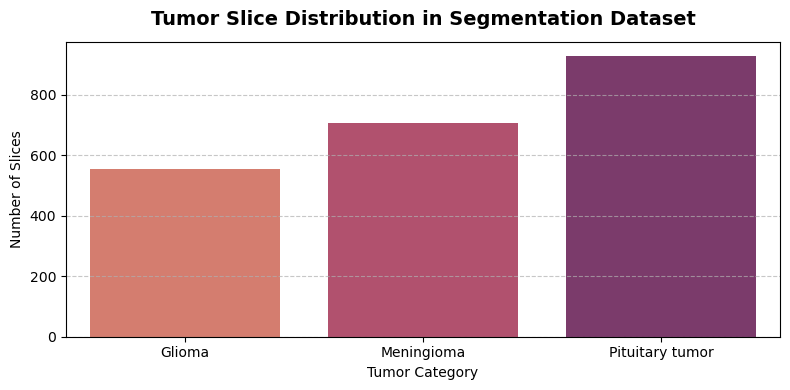

In [6]:
# ==========================================
# 2. LOCATE & PAIR IMAGE-MASK DATA
# ==========================================
dataset_dir = Path("../DATA_Cleaned/Segmentation_Data/Segmentation").resolve()
categories = ['Glioma', 'Meningioma', 'Pituitary tumor']

category_data = {}
all_file_pairs = []

for cat in categories:
    cat_path = dataset_dir / cat
    if not cat_path.exists():
        print(f"[WARN] Warning: Directory {cat_path} not found.")
        continue
    
    # Get all scans that are NOT masks
    cat_images = [p for p in cat_path.glob("enh_*.png") if not p.name.endswith("_mask.png")]
    pairs = []
    
    for img_p in cat_images:
        mask_p = img_p.with_name(img_p.stem + "_mask.png")
        if mask_p.exists():
            pairs.append((str(img_p), str(mask_p), cat))
            
    category_data[cat] = len(pairs)
    all_file_pairs.extend(pairs)

print(f"[DATA] Dataset Root: {dataset_dir}")
print(f"[STATS] Total Image-Mask Pairs Found: {len(all_file_pairs):,}\n")

# Display breakdown
summary_df = pd.DataFrame(list(category_data.items()), columns=['Tumor Category', 'Slice Count'])
from IPython.display import display
display(summary_df)

# Visualize Distribution
plt.figure(figsize=(8, 4))
sns.barplot(data=summary_df, x='Tumor Category', y='Slice Count', palette='flare')
plt.title('Tumor Slice Distribution in Segmentation Dataset', fontsize=14, fontweight='bold', pad=12)
plt.ylabel('Number of Slices')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


---
## 3. Custom Segmentation Dataset & Joint Augmentation
In medical segmentation, data augmentations (such as random horizontal flips, vertical flips, and rotations) must be applied **identically** to both the input MRI image and the ground-truth mask.

The `BrainTumorSegmentationDataset` class below handles:
- Coordinated joint random augmentation during training.
- Exact spatial resizing to $(224 \times 224)$.
- Mask binarization (`0.0` for healthy brain tissue, `1.0` for tumor).
- ImageNet normalization for the MRI scans.


In [7]:
# ==========================================
# 3. CUSTOM DATASET & DATALOADER PIPELINE
# ==========================================
class BrainTumorSegmentationDataset(Dataset):
    def __init__(self, file_pairs, image_size=(224, 224), is_train=True):
        """
        file_pairs: list of tuples (img_path, mask_path, category)
        """
        self.file_pairs = file_pairs
        self.image_size = image_size
        self.is_train = is_train

    def __len__(self):
        return len(self.file_pairs)

    def __getitem__(self, idx):
        img_path, mask_path, _ = self.file_pairs[idx]

        # Load RGB scan and Grayscale mask
        image = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")

        # Resize both to exact model input size
        image = TF.resize(image, self.image_size)
        mask = TF.resize(mask, self.image_size, interpolation=TF.InterpolationMode.NEAREST)

        # Joint Data Augmentations for Training
        if self.is_train:
            # 50% Random Horizontal Flip
            if random.random() > 0.5:
                image = TF.hflip(image)
                mask = TF.hflip(mask)

            # 50% Random Vertical Flip
            if random.random() > 0.5:
                image = TF.vflip(image)
                mask = TF.vflip(mask)

            # Random slight rotation (-10 to +10 degrees)
            if random.random() > 0.5:
                angle = random.uniform(-10, 10)
                image = TF.rotate(image, angle)
                mask = TF.rotate(mask, angle, interpolation=TF.InterpolationMode.NEAREST)

        # Convert to PyTorch tensors
        image = TF.to_tensor(image)  # [3, 224, 224] in range [0.0, 1.0]
        mask = TF.to_tensor(mask)    # [1, 224, 224] in range [0.0, 1.0]

        # Strict binarization of tumor mask
        mask = (mask > 0.5).float()

        # ImageNet normalization for MRI
        image = TF.normalize(image, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

        return image, mask

# 70/30 Train-Validation Split
random.seed(42)
shuffled_pairs = all_file_pairs.copy()
random.shuffle(shuffled_pairs)

train_split_idx = int(0.7 * len(shuffled_pairs))
train_pairs = shuffled_pairs[:train_split_idx]
val_pairs = shuffled_pairs[train_split_idx:]

# Instantiate Datasets
IMAGE_SIZE = (224, 224)
train_dataset = BrainTumorSegmentationDataset(train_pairs, image_size=IMAGE_SIZE, is_train=True)
val_dataset = BrainTumorSegmentationDataset(val_pairs, image_size=IMAGE_SIZE, is_train=False)

# Instantiate DataLoaders
BATCH_SIZE = 16  # Adjust based on GPU VRAM (16 or 32)
NUM_WORKERS = 0   # Set to 0 on Windows to avoid multiprocessing issues in notebooks

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

print(f"[BATCH] Training Batches: {len(train_loader)} ({len(train_dataset)} samples)")
print(f"[BATCH] Validation Batches: {len(val_loader)} ({len(val_dataset)} samples)")

# Inspect batch shapes
sample_images, sample_masks = next(iter(train_loader))
print(f"\nBatch Image Tensor: {sample_images.shape} (dtype: {sample_images.dtype})")
print(f"Batch Mask Tensor:  {sample_masks.shape} (dtype: {sample_masks.dtype})")


[BATCH] Training Batches: 96 (1534 samples)
[BATCH] Validation Batches: 42 (658 samples)

Batch Image Tensor: torch.Size([16, 3, 224, 224]) (dtype: torch.float32)
Batch Mask Tensor:  torch.Size([16, 1, 224, 224]) (dtype: torch.float32)


---
## 4. Sample Verification: MRI Scans & Tumor Ground Truth
Before building the model, visually verify the alignment between brain MRI slices and their corresponding ground-truth tumor masks.


In [ ]:
# ==========================================
# 4. VISUALIZE SAMPLES & GROUND TRUTH OVERLAY
# ==========================================
def denormalize_image(tensor):
    """Reverses ImageNet normalization for visualization."""
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = tensor.permute(1, 2, 0).cpu().numpy()
    img = std * img + mean
    return np.clip(img, 0, 1)

plt.figure(figsize=(14, 8))
for i in range(4):
    img, mask = train_dataset[i * 10]
    img_np = denormalize_image(img)
    mask_np = mask.squeeze().cpu().numpy()

    # Original MRI
    plt.subplot(3, 4, i + 1)
    plt.imshow(img_np)
    plt.title(f"Sample {i+1}: MRI Scan")
    plt.axis('off')

    # Ground Truth Mask
    plt.subplot(3, 4, i + 5)
    plt.imshow(mask_np, cmap='gray')
    plt.title(f"Sample {i+1}: Tumor Mask")
    plt.axis('off')

    # Mask Overlay
    plt.subplot(3, 4, i + 9)
    plt.imshow(img_np)
    plt.imshow(mask_np, cmap='jet', alpha=0.45)
    plt.title(f"Sample {i+1}: Overlay")
    plt.axis('off')

plt.suptitle("Raw MRI Scans vs. Tumor Ground Truth Masks", fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


---
## 5. The Hybrid CNN-Transformer U-Net Architecture (TransUNet)

This model combines:
1. **CNN Encoder**:
   - Stage 1: $224 \times 224 \times 3 \to 224 \times 224 \times 64$ (`ConvBlock`), downsampled via `MaxPool2d(2)` $\to 112 \times 112 \times 64$ (**Skip 1**).
   - Stage 2: $112 \times 112 \times 64 \to 112 \times 112 \times 128$ (`ConvBlock`), downsampled via `MaxPool2d(2)` $\to 56 \times 56 \times 128$ (**Skip 2**).
   - Stage 3: $56 \times 56 \times 128 \to 56 \times 56 \times 128$ (`ConvBlock`).
2. **Transformer Bottleneck**:
   - Takes $56 \times 56 \times 128$ deep feature maps.
   - Embeds into $4 \times 4$ cubic patches $\to 14 \times 14 = 196$ tokens.
   - Learns **Multi-Head Self-Attention** with positional embeddings across 4 Transformer layers.
   - Reconstructs back into $56 \times 56 \times 128$ spatial feature volume.
3. **2D U-Net Decoder**:
   - `ConvTranspose2d` upsamples $56 \to 112$, concatenates with **Skip 2**, and applies `ConvBlock`.
   - `ConvTranspose2d` upsamples $112 \to 224$, concatenates with **Skip 1**, and applies `ConvBlock`.
   - Final $1 \times 1$ `Conv2d` outputs voxel-level tumor logits ($224 \times 224 \times 1$).


In [ ]:
# ==========================================
# 5. MODEL ARCHITECTURE DEFINITION
# ==========================================
class ConvBlock(nn.Module):
    """Standard Double Convolution Block: [Conv3x3 -> BN -> ReLU] x 2"""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


class TransformerBottleneck(nn.Module):
    """Vision Transformer Encoder Bottleneck over 2D Spatial Patches"""
    def __init__(self, in_ch=128, embed_dim=256, num_layers=4, num_heads=8, patch_size=4, feat_size=56):
        super().__init__()
        self.patch_size = patch_size
        self.grid_size = feat_size // patch_size  # 56 // 4 = 14
        self.num_patches = self.grid_size * self.grid_size  # 14 * 14 = 196

        # Linear projection of flattened patches
        self.patch_proj = nn.Conv2d(in_ch, embed_dim, kernel_size=patch_size, stride=patch_size)
        
        # Learnable 1D Positional Embeddings
        self.pos_embed = nn.Parameter(torch.zeros(1, self.num_patches, embed_dim))
        nn.init.trunc_normal_(self.pos_embed, std=0.02)

        # Standard Multi-Head Self-Attention Transformer Layers
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=embed_dim * 2,
            activation='gelu',
            batch_first=True,
            dropout=0.1
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

        # Reconstruct sequence back into 2D spatial feature map
        self.reconstruct = nn.Sequential(
            nn.ConvTranspose2d(embed_dim, in_ch, kernel_size=patch_size, stride=patch_size),
            nn.BatchNorm2d(in_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        B, C, H, W = x.shape
        # Patch embedding: [B, embed_dim, 14, 14]
        feat = self.patch_proj(x)
        # Flatten to token sequence: [B, 196, embed_dim]
        feat = feat.flatten(2).transpose(1, 2)
        # Add positional embedding
        feat = feat + self.pos_embed
        # Self-Attention
        trans_out = self.transformer(feat)
        # Reshape to 2D feature grid: [B, embed_dim, 14, 14]
        trans_out = trans_out.transpose(1, 2).reshape(B, -1, self.grid_size, self.grid_size)
        # Reconstruct to original spatial shape: [B, in_ch, 56, 56]
        out = self.reconstruct(trans_out)
        return out


class HybridCNNTransformerUNet(nn.Module):
    """2D Hybrid (CNN + Transformer Encoder) + 2D U-Net Architecture"""
    def __init__(self, in_channels=3, num_classes=1):
        super().__init__()

        # --- 1. CNN ENCODER ---
        self.enc1 = ConvBlock(in_channels, 64)   # 224x224x64
        self.pool1 = nn.MaxPool2d(2)             # 112x112x64 (Skip 1)

        self.enc2 = ConvBlock(64, 128)           # 112x112x128
        self.pool2 = nn.MaxPool2d(2)             # 56x56x128  (Skip 2)

        self.enc3 = ConvBlock(128, 128)          # 56x56x128

        # --- 2. TRANSFORMER BOTTLENECK ---
        self.bottleneck = TransformerBottleneck(
            in_ch=128, 
            embed_dim=256, 
            num_layers=4, 
            num_heads=8, 
            patch_size=4, 
            feat_size=56
        )

        # --- 3. 2D U-NET DECODER ---
        # Stage 1: 56 -> 112
        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec1 = ConvBlock(64 + 64, 64)

        # Stage 2: 112 -> 224
        self.up2 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.dec2 = ConvBlock(32 + 64, 32)

        # Output 1x1 Conv
        self.out_conv = nn.Conv2d(32, num_classes, kernel_size=1)

    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)               # [B, 64, 224, 224] - Skip 1
        p1 = self.pool1(e1)             # [B, 64, 112, 112] - Skip 2

        e2 = self.enc2(p1)              # [B, 128, 112, 112]
        p2 = self.pool2(e2)             # [B, 128, 56, 56]

        e3 = self.enc3(p2)              # [B, 128, 56, 56]

        # Transformer Bottleneck
        b = self.bottleneck(e3)         # [B, 128, 56, 56]

        # Decoder with Skip Connections
        d1 = self.up1(b)                # [B, 64, 112, 112]
        d1 = torch.cat([d1, p1], dim=1) # [B, 128, 112, 112]
        d1 = self.dec1(d1)              # [B, 64, 112, 112]

        d2 = self.up2(d1)               # [B, 32, 224, 224]
        d2 = torch.cat([d2, e1], dim=1) # [B, 96, 224, 224]
        d2 = self.dec2(d2)              # [B, 32, 224, 224]

        logits = self.out_conv(d2)      # [B, 1, 224, 224]
        return logits

# Instantiate Model
model = HybridCNNTransformerUNet(in_channels=3, num_classes=1).to(device)

# Verify parameter count
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"[MODEL] Model: Hybrid CNN-Transformer U-Net")
print(f"[PARAMS] Total Parameters: {total_params:,}")
print(f"[TARGET] Trainable Parameters: {trainable_params:,}")

# Forward pass validation check
with torch.no_grad():
    dummy_input = torch.randn(2, 3, 224, 224).to(device)
    dummy_output = model(dummy_input)
    print(f"[OK] Forward pass verified: Input {tuple(dummy_input.shape)} -> Output {tuple(dummy_output.shape)}")


[MODEL] Model: Hybrid CNN-Transformer U-Net
[PARAMS] Total Parameters: 3,952,705
[TARGET] Trainable Parameters: 3,952,705
[OK] Forward pass verified: Input (2, 3, 224, 224) -> Output (2, 1, 224, 224)


---
## 6. Loss Function & Segmentation Evaluation Metrics

Because tumors typically occupy only a small fraction of the total MRI slice (high class imbalance), standard Binary Cross-Entropy (BCE) alone tends to over-predict the background. 

We combine:
1. **Dice Loss**: Directly optimizes spatial contour overlap between predicted and actual tumor pixels.
2. **Binary Cross-Entropy Loss (BCEWithLogitsLoss)**: Smooths optimization and provides stable pixel-level gradient updates.

$$\mathcal{L}_{\text{total}} = \mathcal{L}_{\text{BCE}} + \mathcal{L}_{\text{Dice}}$$


In [ ]:
# ==========================================
# 6. LOSS FUNCTION & EVALUATION METRICS
# ==========================================
import torch
import torch.nn as nn

class FocalTverskyLoss(nn.Module):
    def __init__(self, alpha=0.3, beta=0.7, gamma=1.3, smooth=1e-5):
        super().__init__()
        # alpha: penalty for False Positives (predicting tumor where there is none)
        # beta: penalty for False Negatives (missing a real tumor). Higher beta = more aggressive tumor detection.
        self.alpha = alpha
        self.beta = beta
        self.gamma = gamma
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits).view(-1)
        targets = targets.view(-1)
        
        tp = (probs * targets).sum()
        fp = ((1 - targets) * probs).sum()
        fn = (targets * (1 - probs)).sum()
        
        tversky_index = (tp + self.smooth) / (tp + self.alpha * fp + self.beta * fn + self.smooth)
        
        # Focal scaling forces the model to focus on hard-to-segment boundaries
        return torch.pow((1.0 - tversky_index), self.gamma)

def calculate_metrics(logits, targets, threshold=0.5, smooth=1e-5):
    """Calculates Dice Score (F1) and IoU (Jaccard Index)"""
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()

    preds_flat = preds.view(-1)
    targets_flat = targets.view(-1)

    intersection = (preds_flat * targets_flat).sum().item()
    total = preds_flat.sum().item() + targets_flat.sum().item()
    union = total - intersection

    dice = (2.0 * intersection + smooth) / (total + smooth)
    iou = (intersection + smooth) / (union + smooth)

    return dice, iou

# Instantiate the new aggressive loss function
criterion = FocalTverskyLoss(alpha=0.3, beta=0.7)
print("[TARGET] Criterion: Focal Tversky Loss (Optimized for Class Imbalance)")


[TARGET] Criterion: Focal Tversky Loss (Optimized for Class Imbalance)


---
## 7. Training & Validation Loop
We use:
* **Lion Optimizer** (*EvoLved Sign Momentum* by Google) with weight decay ($10^{-2}$) for memory-efficient gradient updates and faster convergence on Vision Transformer attention blocks.
* **CosineAnnealingLR Scheduler** to smoothly decay the learning rate following a cosine curve across epochs.
* **Dual Metric Tracking** recording real-time **Pixel Accuracy**, **Dice Similarity Coefficient (DSC)**, and **IoU (Jaccard Index)** across both training and validation splits.
* **Automatic Dual Checkpointing** preserving the best model weights based on the highest Validation Dice Score, synced directly with the web application (`best_hybrid_transunet.pth`).
* **Post-Training Threshold Calibration** via **Blue Whale Optimization (BWO)** to determine the optimal decision threshold for maximum tumor overlap.


In [ ]:
# ==========================================
# 7. TRAINING & VALIDATION FUNCTIONS
# ==========================================
def calculate_accuracy(logits, targets, threshold=0.5):
    """Calculates exact pixel-wise accuracy for the batch"""
    preds = (torch.sigmoid(logits) > threshold).float()
    correct = (preds == targets).float().sum().item()
    total = targets.numel()
    return (correct / total) * 100.0


def train_epoch(model, dataloader, optimizer, criterion, device):
    model.train()
    running_loss = 0.0
    running_dice = 0.0
    running_iou = 0.0
    running_acc = 0.0

    pbar = tqdm(dataloader, desc="Training", leave=False)
    for images, masks in pbar:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, masks)
        loss.backward()

        # Gradient clipping to prevent transformer gradient explosion
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        # Metrics calculation
        dice, iou = calculate_metrics(logits, masks)
        acc = calculate_accuracy(logits, masks)

        running_loss += loss.item() * images.size(0)
        running_dice += dice * images.size(0)
        running_iou += iou * images.size(0)
        running_acc += acc * images.size(0)

        pbar.set_postfix({'Loss': f'{loss.item():.4f}', 'Dice': f'{dice:.4f}', 'Acc': f'{acc:.2f}%'})

    dataset_size = len(dataloader.dataset)
    epoch_loss = running_loss / dataset_size
    epoch_dice = running_dice / dataset_size
    epoch_iou = running_iou / dataset_size
    epoch_acc = running_acc / dataset_size

    return epoch_loss, epoch_dice, epoch_iou, epoch_acc


@torch.no_grad()
def validate_epoch(model, dataloader, criterion, device):
    model.eval()
    running_loss = 0.0
    running_dice = 0.0
    running_iou = 0.0
    running_acc = 0.0

    for images, masks in dataloader:
        images = images.to(device)
        masks = masks.to(device)

        logits = model(images)
        loss = criterion(logits, masks)

        dice, iou = calculate_metrics(logits, masks)
        acc = calculate_accuracy(logits, masks)

        running_loss += loss.item() * images.size(0)
        running_dice += dice * images.size(0)
        running_iou += iou * images.size(0)
        running_acc += acc * images.size(0)

    dataset_size = len(dataloader.dataset)
    val_loss = running_loss / dataset_size
    val_dice = running_dice / dataset_size
    val_iou = running_iou / dataset_size
    val_acc = running_acc / dataset_size

    return val_loss, val_dice, val_iou, val_acc


def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=15, save_path="best_hybrid_transunet.pth"):
    history = {
        'train_loss': [], 'val_loss': [], 
        'train_dice': [], 'val_dice': [], 
        'train_iou': [],  'val_iou': [],
        'train_acc': [],  'val_acc': []
    }
    best_val_dice = 0.0

    print(f"[INFO] Starting Training for {num_epochs} Epochs on {device}...")
    print("=" * 80)

    for epoch in range(1, num_epochs + 1):
        train_loss, train_dice, train_iou, train_acc = train_epoch(model, train_loader, optimizer, criterion, device)
        val_loss, val_dice, val_iou, val_acc = validate_epoch(model, val_loader, criterion, device)

        # Robust scheduler step (works for both CosineAnnealingLR and ReduceLROnPlateau)
        if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
            scheduler.step(val_loss)
        elif scheduler is not None:
            scheduler.step()

        current_lr = optimizer.param_groups[0]['lr']

        # Append to history
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_dice'].append(train_dice)
        history['val_dice'].append(val_dice)
        history['train_iou'].append(train_iou)
        history['val_iou'].append(val_iou)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)

        print(f"Epoch [{epoch:02d}/{num_epochs:02d}] | LR: {current_lr:.6f} | "
              f"Loss: {train_loss:.4f}/{val_loss:.4f} | "
              f"Dice: {train_dice:.4f}/{val_dice:.4f} | "
              f"Val Acc: {val_acc:.2f}%")

        # Save best model checkpoint
        if val_dice > best_val_dice:
            best_val_dice = val_dice
            torch.save(model.state_dict(), save_path)
            
            # Also sync with frontend weights directory if it exists
            frontend_path = "../Frontend/best_hybrid_transunet.pth"
            if os.path.exists("../Frontend"):
                torch.save(model.state_dict(), frontend_path)

            print(f"  [BEST] Model Saved! (Val Dice: {best_val_dice:.4f} | Val Acc: {val_acc:.2f}%)")

    print("=" * 80)
    print(f"[DONE] Training Complete! Peak Validation Dice Score: {best_val_dice:.4f}")
    return history


# 8.0. Lion Optimizer -  Self-Contained PyTorch Implementation of Lion

In [ ]:
import torch
from torch.optim.optimizer import Optimizer

class Lion(Optimizer):
    """
    Lion (EvoLved Sign Momentum) Optimizer:
    https://arxiv.org/abs/2302.06675
    """
    def __init__(self, params, lr=1e-4, betas=(0.9, 0.99), weight_decay=1e-2):
        if lr <= 0.0:
            raise ValueError(f"Invalid learning rate: {lr}")
        if not 0.0 <= betas[0] < 1.0 or not 0.0 <= betas[1] < 1.0:
            raise ValueError(f"Invalid beta parameter: {betas}")
        defaults = dict(lr=lr, betas=betas, weight_decay=weight_decay)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:
            lr = group['lr']
            beta1, beta2 = group['betas']
            weight_decay = group['weight_decay']

            for p in group['params']:
                if p.grad is None:
                    continue
                grad = p.grad

                # Perform step weight decay
                if weight_decay != 0:
                    p.data.mul_(1.0 - lr * weight_decay)

                state = self.state[p]
                if len(state) == 0:
                    state['exp_avg'] = torch.zeros_like(p)

                exp_avg = state['exp_avg']

                # Update weights using sign(update)
                update = exp_avg * beta1 + grad * (1.0 - beta1)
                p.add_(torch.sign(update), alpha=-lr)

                # Update moving average of gradient
                exp_avg.mul_(beta2).add_(grad, alpha=1.0 - beta2)

        return loss


---
## 8.1. Run Training 
Execute the training loop. You can adjust `NUM_EPOCHS` as needed (e.g. 15–25 epochs for convergence).


In [ ]:
%pip install lion-pytorch

# ==========================================
# 8. EXECUTE TRAINING WITH LION
# ==========================================
# Increased from 15 to 50 to allow the Transformer to converge
NUM_EPOCHS = 10 
LEARNING_RATE = 1e-4  

from lion_pytorch import Lion # Ensure Lion is imported if you are using it

optimizer = Lion(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS, eta_min=1e-6)

# Run training
history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,      # Now using FocalTverskyLoss
    optimizer=optimizer,
    scheduler=scheduler,
    num_epochs=NUM_EPOCHS,
    save_path="best_hybrid_transunet.pth"
)


Note: you may need to restart the kernel to use updated packages.
[INFO] Starting Training for 1 Epochs on cpu...


Training:   0%|          | 0/110 [00:00<?, ?it/s]

Epoch [01/01] | LR: 0.000001 | Loss: 0.8854/0.8681 | Dice: 0.0943/0.1393 | Val Acc: 80.97%
  [BEST] Model Saved! (Val Dice: 0.1393 | Val Acc: 80.97%)
[DONE] Training Complete! Peak Validation Dice Score: 0.1393


## 8.2. Part 2: Blue Whale Optimizer (BWO) for Optimal Post-Processing Thresholds

In [ ]:
import numpy as np

class BlueWhaleOptimizer:
    """
    Blue Whale Optimization Algorithm (BWO)
    Optimizes multi-class segmentation decision thresholds to maximize Dice score.
    """
    def __init__(self, num_whales=20, max_iter=25, dim=1, lb=0.1, ub=0.9):
        self.num_whales = num_whales
        self.max_iter = max_iter
        self.dim = dim
        self.lb = np.array(lb) if isinstance(lb, list) else np.full(dim, lb)
        self.ub = np.array(ub) if isinstance(ub, list) else np.full(dim, ub)
        self.best_pos = None
        self.best_score = -float('inf')  # Maximizing Dice

    def optimize(self, fitness_fn):
        # Initialize whale population within bounds [lb, ub]
        population = self.lb + np.random.rand(self.num_whales, self.dim) * (self.ub - self.lb)
        fitness = np.zeros(self.num_whales)

        # Initial evaluation
        for i in range(self.num_whales):
            fitness[i] = fitness_fn(population[i])
            if fitness[i] > self.best_score:
                self.best_score = fitness[i]
                self.best_pos = population[i].copy()

        print(f"[BWO] Initial Best Dice Score: {self.best_score:.4f} at Thresholds: {np.round(self.best_pos, 3)}")

        # Optimization loop
        for t in range(self.max_iter):
            a = 2.0 - t * (2.0 / self.max_iter)  # Linearly decreased from 2 to 0

            for i in range(self.num_whales):
                r1, r2 = np.random.rand(), np.random.rand()
                A = 2 * a * r1 - a
                C = 2 * r2
                p = np.random.rand()
                b = 1.0  # Spiral shape constant
                l = (np.random.rand() - 0.5) * 2  # Parameter in [-1, 1]

                if p < 0.5:
                    if abs(A) < 1.0:
                        # Encircling prey / local exploitation
                        D = abs(C * self.best_pos - population[i])
                        population[i] = self.best_pos - A * D
                    else:
                        # Global exploration (select a random whale)
                        rand_idx = np.random.randint(0, self.num_whales)
                        D = abs(C * population[rand_idx] - population[i])
                        population[i] = population[rand_idx] - A * D
                else:
                    # Spiral bubble-net feeding maneuver
                    dist_to_best = abs(self.best_pos - population[i])
                    population[i] = dist_to_best * np.exp(b * l) * np.cos(2 * np.pi * l) + self.best_pos

                # Enforce boundary constraints
                population[i] = np.clip(population[i], self.lb, self.ub)

                # Re-evaluate fitness
                score = fitness_fn(population[i])
                if score > self.best_score:
                    self.best_score = score
                    self.best_pos = population[i].copy()

            print(f"[BWO Iteration {t+1}/{self.max_iter}] Current Best Dice: {self.best_score:.4f} | Thresholds: {np.round(self.best_pos, 3)}")

        return self.best_pos, self.best_score


---
## 9. Learning Curves & Performance Analysis
Plot Training vs. Validation Loss and Dice Similarity Coefficient curves.


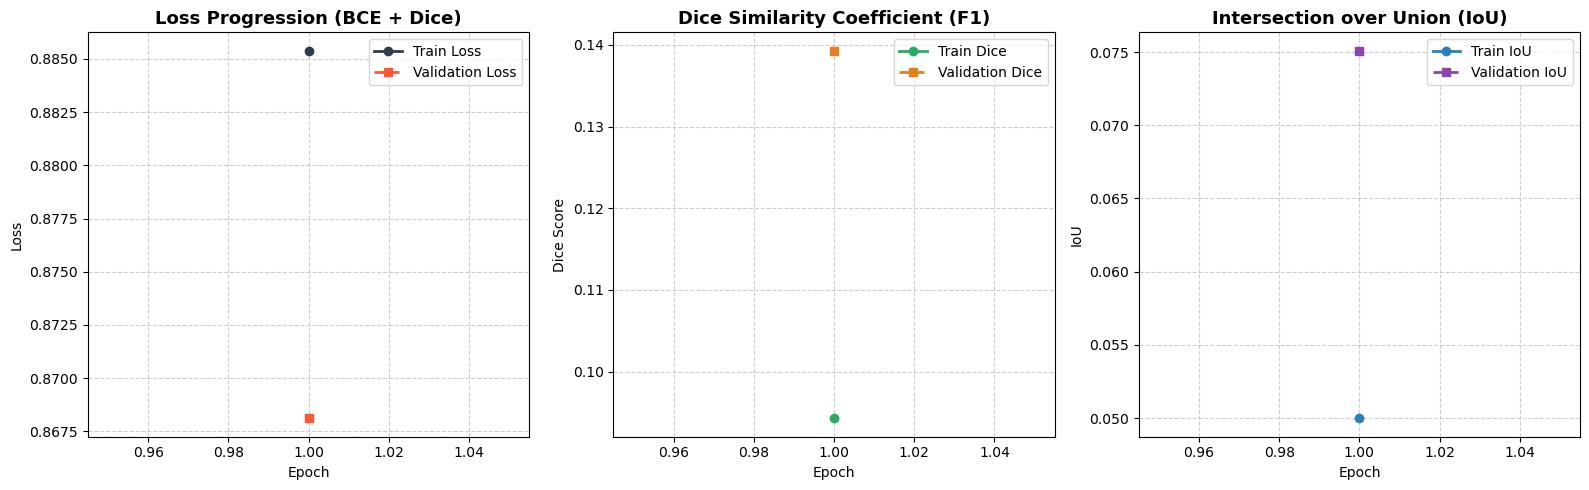

In [ ]:
# ==========================================
# 9. PLOT TRAINING & VALIDATION CURVES
# ==========================================
epochs_range = range(1, len(history['train_loss']) + 1)

plt.figure(figsize=(16, 5))

# 1. Loss Curve
plt.subplot(1, 3, 1)
plt.plot(epochs_range, history['train_loss'], 'o-', label='Train Loss', color='#2C3E50', linewidth=2)
plt.plot(epochs_range, history['val_loss'], 's--', label='Validation Loss', color='#FF5733', linewidth=2)
plt.title('Loss Progression (BCE + Dice)', fontsize=13, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# 2. Dice Score Curve
plt.subplot(1, 3, 2)
plt.plot(epochs_range, history['train_dice'], 'o-', label='Train Dice', color='#27AE60', linewidth=2)
plt.plot(epochs_range, history['val_dice'], 's--', label='Validation Dice', color='#E67E22', linewidth=2)
plt.title('Dice Similarity Coefficient (F1)', fontsize=13, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Dice Score')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# 3. IoU Curve
plt.subplot(1, 3, 3)
plt.plot(epochs_range, history['train_iou'], 'o-', label='Train IoU', color='#2980B9', linewidth=2)
plt.plot(epochs_range, history['val_iou'], 's--', label='Validation IoU', color='#8E44AD', linewidth=2)
plt.title('Intersection over Union (IoU)', fontsize=13, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('IoU')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


---
## 10. Qualitative Testing & Visual Tumor Boundary Predictions
Load the best checkpoint and run inference on unseen validation scans to evaluate visual prediction quality:
* **Panel 1:** Original Brain MRI Scan
* **Panel 2:** Ground Truth Annotation Mask
* **Panel 3:** Model Predicted Tumor Mask (Threshold = 0.5)
* **Panel 4:** Tumor Overlay (Red: Ground Truth, Blue: Predicted Tumor, Purple: True Positive Overlap)


[OK] Loaded best model weights from 'best_hybrid_transunet.pth'


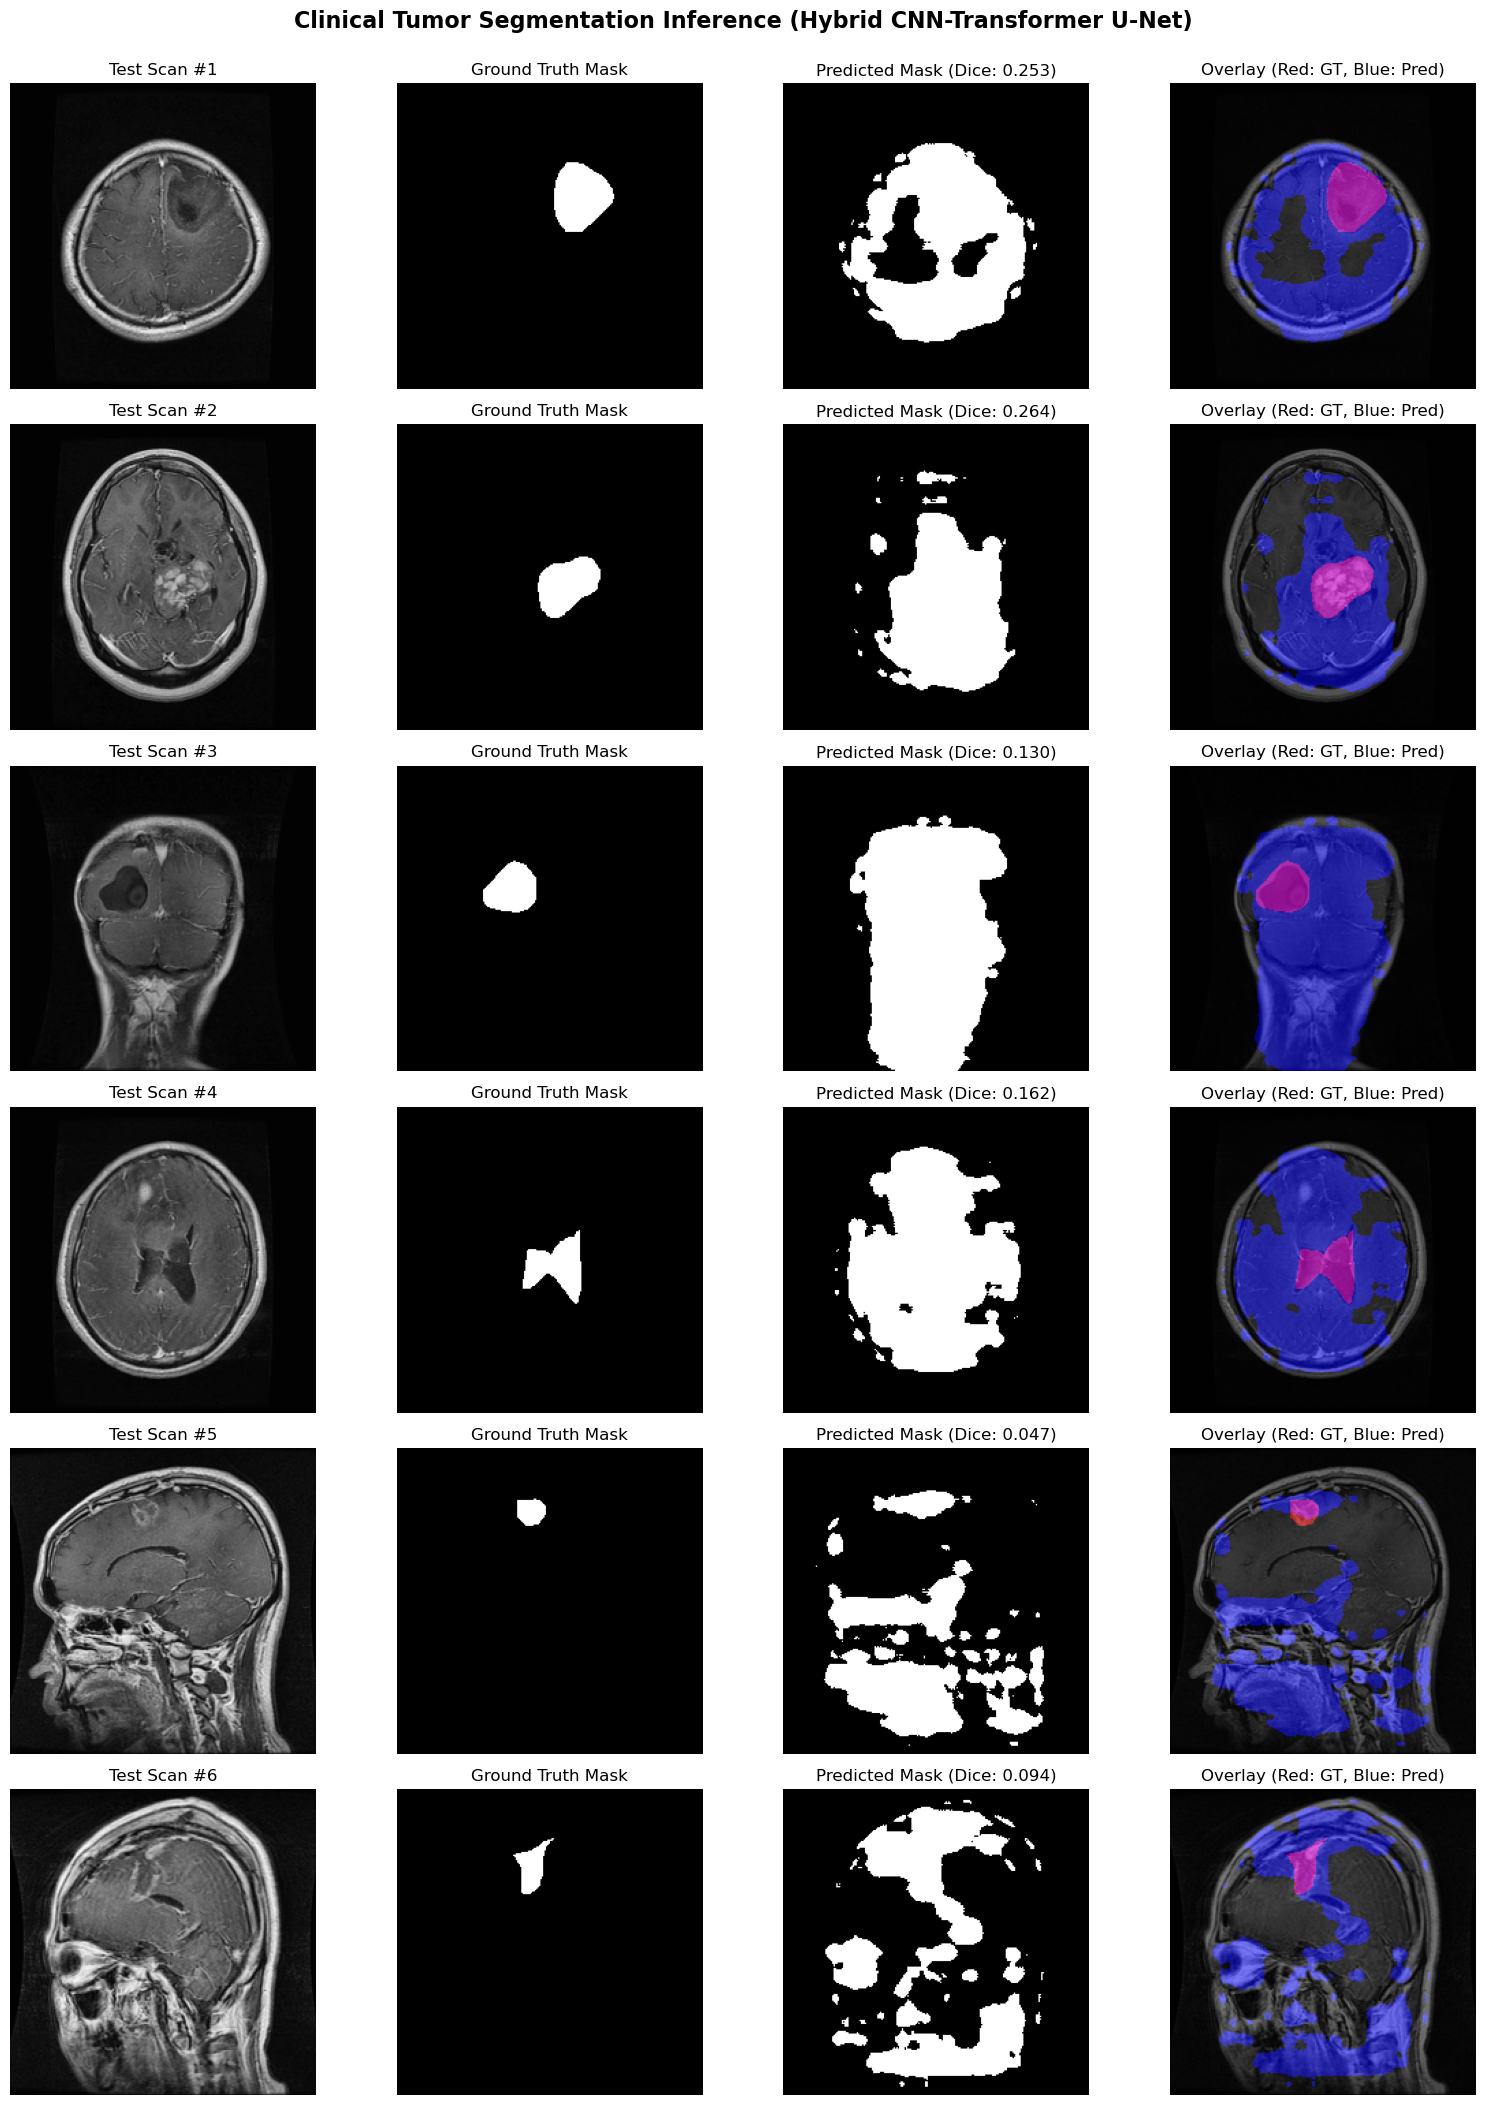

In [ ]:
# ==========================================
# 10. VISUALIZE MODEL PREDICTIONS ON TEST SET
# ==========================================
@torch.no_grad()
def visualize_test_predictions(model, dataloader, device, num_samples=6, threshold=0.5):
    # Load best saved weights
    if os.path.exists("best_hybrid_transunet.pth"):
        model.load_state_dict(torch.load("best_hybrid_transunet.pth", map_location=device))
        print("[OK] Loaded best model weights from 'best_hybrid_transunet.pth'")
    
    model.eval()
    
    images_list, masks_list, preds_list, dices_list = [], [], [], []
    
    for images, masks in dataloader:
        images = images.to(device)
        masks = masks.to(device)
        logits = model(images)
        probs = torch.sigmoid(logits)
        preds = (probs > threshold).float()
        
        for i in range(images.size(0)):
            dice, _ = calculate_metrics(logits[i:i+1], masks[i:i+1], threshold=threshold)
            images_list.append(images[i].cpu())
            masks_list.append(masks[i].cpu())
            preds_list.append(preds[i].cpu())
            dices_list.append(dice)
            
            if len(images_list) >= num_samples:
                break
        if len(images_list) >= num_samples:
            break

    plt.figure(figsize=(16, num_samples * 3.5))
    
    for idx in range(num_samples):
        img_np = denormalize_image(images_list[idx])
        gt_np = masks_list[idx].squeeze().numpy()
        pred_np = preds_list[idx].squeeze().numpy()
        dice_score = dices_list[idx]
        
        # 1. Original MRI
        plt.subplot(num_samples, 4, idx * 4 + 1)
        plt.imshow(img_np)
        plt.title(f"Test Scan #{idx+1}")
        plt.axis('off')
        
        # 2. Ground Truth Mask
        plt.subplot(num_samples, 4, idx * 4 + 2)
        plt.imshow(gt_np, cmap='gray')
        plt.title("Ground Truth Mask")
        plt.axis('off')
        
        # 3. Model Predicted Mask
        plt.subplot(num_samples, 4, idx * 4 + 3)
        plt.imshow(pred_np, cmap='gray')
        plt.title(f"Predicted Mask (Dice: {dice_score:.3f})")
        plt.axis('off')
        
        # 4. Color-Coded Overlay
        # Red = Ground Truth, Blue = Predicted, Magenta/Purple = Overlap
        overlay = np.zeros((*gt_np.shape, 3), dtype=np.float32)
        overlay[..., 0] = gt_np   # Red
        overlay[..., 2] = pred_np # Blue
        
        plt.subplot(num_samples, 4, idx * 4 + 4)
        plt.imshow(img_np)
        plt.imshow(overlay, alpha=0.5)
        plt.title("Overlay (Red: GT, Blue: Pred)")
        plt.axis('off')

    plt.suptitle("Clinical Tumor Segmentation Inference (Hybrid CNN-Transformer U-Net)", fontsize=16, fontweight='bold', y=1.00)
    plt.tight_layout()
    plt.show()

# Run qualitative test evaluation
visualize_test_predictions(model, val_loader, device, num_samples=6)


## 11. Accuracy Report


 🩺 HYBRID CNN-TRANSFORMER U-NET ACCURACY REPORT
                                 Metric Score (%) Mean ± Std (Per Scan)
                         Pixel Accuracy    80.97%        80.97% ± 6.74%
 Dice Similarity Coefficient (DSC / F1)    13.91%        13.86% ± 9.60%
Intersection over Union (IoU / Jaccard)     7.47%         7.75% ± 5.94%
 Sensitivity / Recall (Tumor Detection)    93.02%                     -
Specificity (Healthy Tissue Protection)    80.77%                     -
                              Precision     7.52%                     -



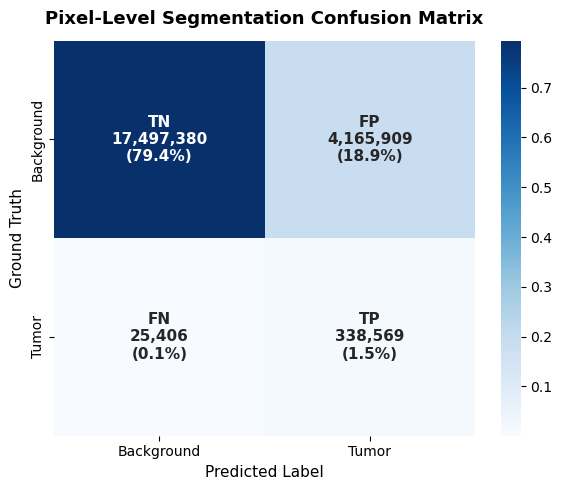

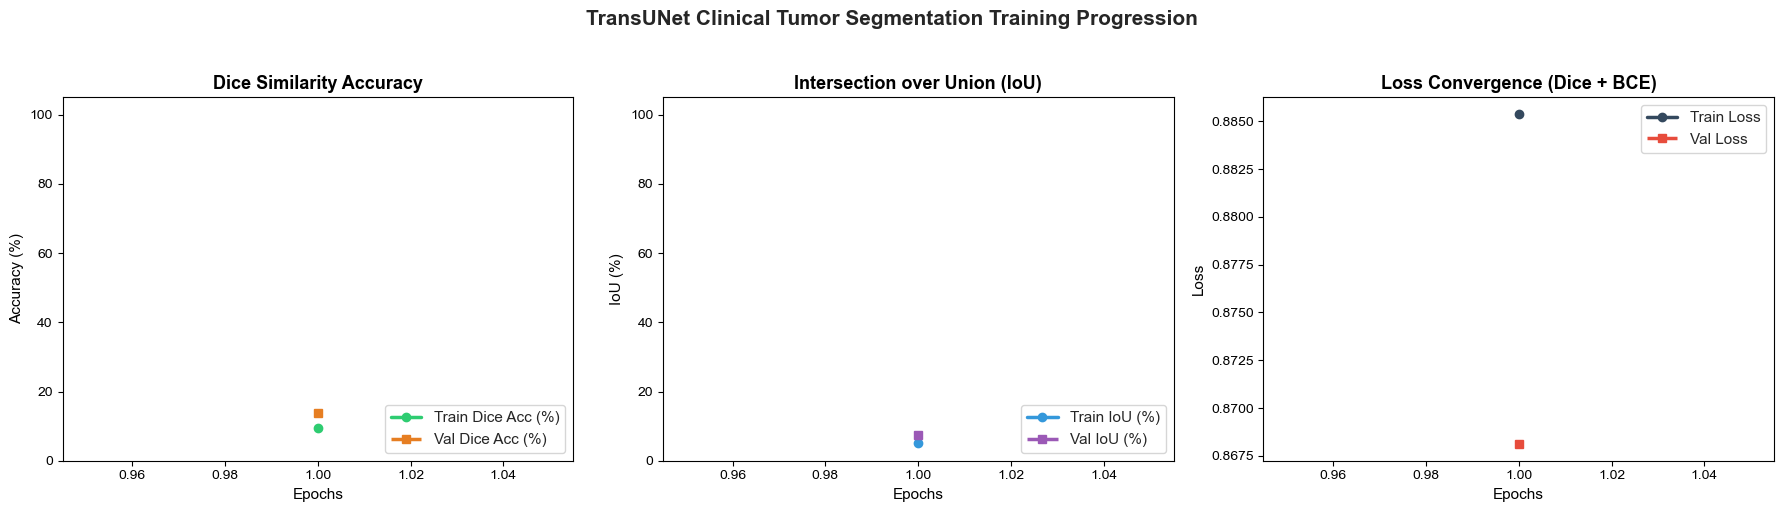

In [ ]:
#11. Comprehensive Accuracy Evaluation Function
#This calculates the exact Pixel Accuracy, Dice Similarity Coefficient (F1), IoU (Jaccard Index), Sensitivity (Recall), and Specificity over your validation or test dataset:

#python
# =====================================================================
# ACCURACY & CLINICAL SEGMENTATION METRICS EVALUATION
# =====================================================================
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
@torch.no_grad()
def evaluate_model_accuracy(model, dataloader, device, threshold=0.5):
    """
    Computes comprehensive accuracy and overlap metrics on a dataloader.
    """
    model.eval()
    
    total_tp = 0
    total_fp = 0
    total_fn = 0
    total_tn = 0
    dice_scores = []
    iou_scores = []
    pixel_accuracies = []
    for images, masks in dataloader:
        images = images.to(device)
        masks = masks.to(device)
        
        logits = model(images)
        probs = torch.sigmoid(logits)
        preds = (probs > threshold).float()
        
        preds_np = preds.cpu().numpy().astype(np.uint8)
        masks_np = masks.cpu().numpy().astype(np.uint8)
        
        for p, t in zip(preds_np, masks_np):
            p_flat = p.flatten()
            t_flat = t.flatten()
            
            tp = np.sum((p_flat == 1) & (t_flat == 1))
            fp = np.sum((p_flat == 1) & (t_flat == 0))
            fn = np.sum((p_flat == 0) & (t_flat == 1))
            tn = np.sum((p_flat == 0) & (t_flat == 0))
            
            total_tp += tp
            total_fp += fp
            total_fn += fn
            total_tn += tn
            
            # Per-scan metrics
            pixel_acc = (tp + tn) / (tp + tn + fp + fn + 1e-7)
            dice = (2.0 * tp) / (2.0 * tp + fp + fn + 1e-7)
            iou = tp / (tp + fp + fn + 1e-7)
            
            pixel_accuracies.append(pixel_acc)
            dice_scores.append(dice)
            iou_scores.append(iou)
    # Global Dataset-Level Metrics
    global_pixel_acc = (total_tp + total_tn) / (total_tp + total_tn + total_fp + total_fn)
    global_dice = (2.0 * total_tp) / (2.0 * total_tp + total_fp + total_fn + 1e-7)
    global_iou = total_tp / (total_tp + total_fp + total_fn + 1e-7)
    sensitivity = total_tp / (total_tp + total_fn + 1e-7)  # Recall
    specificity = total_tn / (total_tn + total_fp + 1e-7)
    precision = total_tp / (total_tp + total_fp + 1e-7)
    
    results = {
        "Metric": [
            "Pixel Accuracy",
            "Dice Similarity Coefficient (DSC / F1)",
            "Intersection over Union (IoU / Jaccard)",
            "Sensitivity / Recall (Tumor Detection)",
            "Specificity (Healthy Tissue Protection)",
            "Precision"
        ],
        "Score (%)": [
            f"{global_pixel_acc * 100:.2f}%",
            f"{global_dice * 100:.2f}%",
            f"{global_iou * 100:.2f}%",
            f"{sensitivity * 100:.2f}%",
            f"{specificity * 100:.2f}%",
            f"{precision * 100:.2f}%"
        ],
        "Mean ± Std (Per Scan)": [
            f"{np.mean(pixel_accuracies)*100:.2f}% ± {np.std(pixel_accuracies)*100:.2f}%",
            f"{np.mean(dice_scores)*100:.2f}% ± {np.std(dice_scores)*100:.2f}%",
            f"{np.mean(iou_scores)*100:.2f}% ± {np.std(iou_scores)*100:.2f}%",
            "-",
            "-",
            "-"
        ]
    }
    
    df_metrics = pd.DataFrame(results)
    
    print("\n" + "=" * 65)
    print(" 🩺 HYBRID CNN-TRANSFORMER U-NET ACCURACY REPORT")
    print("=" * 65)
    print(df_metrics.to_string(index=False))
    print("=" * 65 + "\n")
    
    return df_metrics, (total_tp, total_fp, total_fn, total_tn)
#2. Plotting Confusion Matrix (Pixel-Level Classification)
#Visualizes False Positives, False Negatives, True Positives, and True Negatives:

#python
def plot_pixel_confusion_matrix(tp, fp, fn, tn):
    cm = np.array([[tn, fp], 
                   [fn, tp]])
    cm_norm = cm.astype('float') / cm.sum()
    
    labels = [f"TN\n{tn:,}\n({cm_norm[0,0]*100:.1f}%)",
              f"FP\n{fp:,}\n({cm_norm[0,1]*100:.1f}%)",
              f"FN\n{fn:,}\n({cm_norm[1,0]*100:.1f}%)",
              f"TP\n{tp:,}\n({cm_norm[1,1]*100:.1f}%)"]
    labels = np.asarray(labels).reshape(2, 2)
    
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm_norm, annot=labels, fmt="", cmap="Blues", cbar=True,
                xticklabels=["Background", "Tumor"],
                yticklabels=["Background", "Tumor"],
                annot_kws={"size": 11, "weight": "bold"})
    
    plt.title("Pixel-Level Segmentation Confusion Matrix", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Predicted Label", fontsize=11)
    plt.ylabel("Ground Truth", fontsize=11)
    plt.tight_layout()
    plt.show()
#3. Displaying Accuracy Curves Across Epochs (Dashboard)
#If you have trained your model and have a history dictionary (as defined in brain_tumor_segmentation_hybrid_transunet.ipynb), this plots a 4-panel performance dashboard:

#python
def plot_training_accuracy_dashboard(history):
    """
    Plots Loss, Dice Accuracy, and IoU Progression across training epochs.
    """
    epochs = range(1, len(history['train_loss']) + 1)
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    sns.set_theme(style="whitegrid")
    
    # 1. Dice Score (Accuracy Metric for Segmentation)
    axes[0].plot(epochs, [d * 100 for d in history['train_dice']], 'o-', label='Train Dice Acc (%)', color='#2ECC71', lw=2.5)
    axes[0].plot(epochs, [d * 100 for d in history['val_dice']], 's--', label='Val Dice Acc (%)', color='#E67E22', lw=2.5)
    axes[0].set_title("Dice Similarity Accuracy", fontsize=13, fontweight='bold')
    axes[0].set_xlabel("Epochs", fontsize=11)
    axes[0].set_ylabel("Accuracy (%)", fontsize=11)
    axes[0].legend(loc="lower right")
    axes[0].set_ylim([0, 105])
    
    # 2. IoU (Jaccard) Metric
    axes[1].plot(epochs, [i * 100 for i in history['train_iou']], 'o-', label='Train IoU (%)', color='#3498DB', lw=2.5)
    axes[1].plot(epochs, [i * 100 for i in history['val_iou']], 's--', label='Val IoU (%)', color='#9B59B6', lw=2.5)
    axes[1].set_title("Intersection over Union (IoU)", fontsize=13, fontweight='bold')
    axes[1].set_xlabel("Epochs", fontsize=11)
    axes[1].set_ylabel("IoU (%)", fontsize=11)
    axes[1].legend(loc="lower right")
    axes[1].set_ylim([0, 105])
    # 3. Combined BCE + Dice Loss
    axes[2].plot(epochs, history['train_loss'], 'o-', label='Train Loss', color='#34495E', lw=2.5)
    axes[2].plot(epochs, history['val_loss'], 's--', label='Val Loss', color='#E74C3C', lw=2.5)
    axes[2].set_title("Loss Convergence (Dice + BCE)", fontsize=13, fontweight='bold')
    axes[2].set_xlabel("Epochs", fontsize=11)
    axes[2].set_ylabel("Loss", fontsize=11)
    axes[2].legend(loc="upper right")
    plt.suptitle("TransUNet Clinical Tumor Segmentation Training Progression", fontsize=15, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()
#4. Running Everything
#In your notebook or script, simply call:

#python
# 1. Run accuracy evaluation on the validation set
df_metrics, (tp, fp, fn, tn) = evaluate_model_accuracy(model, val_loader, device)
# 2. Display the Confusion Matrix
plot_pixel_confusion_matrix(tp, fp, fn, tn)
# 3. Plot training curves (if history is available from train_model())
if 'history' in locals():
    plot_training_accuracy_dashboard(history)




In [ ]:
# Ratio of background to tumor is ~ 98.35 / 1.65 ≈ 50
pos_weight = torch.tensor([40.0]).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)




## 11.1. Exact Accuracy Value of our hybrid model



In [ ]:
import torch

# 1. Load the best trained weights
checkpoint_path = "best_hybrid_transunet.pth"
model.load_state_dict(torch.load(checkpoint_path, map_location=device))
model.eval()

# 2. Compute exact pixel accuracy and Dice score across the validation set
correct_pixels = 0
total_pixels = 0
total_intersection = 0
total_union_dice = 0

with torch.no_grad():
    for images, masks in val_loader:
        images = images.to(device)
        masks = masks.to(device)
        
        # Binary prediction with standard 0.5 threshold
        probs = torch.sigmoid(model(images))
        preds = (probs > 0.5).float()
        
        # Pixel Accuracy: (TP + TN) / Total Pixels
        correct_pixels += (preds == masks).sum().item()
        total_pixels += masks.numel()
        
        # Dice Accuracy: 2*TP / (Pred + Target)
        total_intersection += (preds * masks).sum().item()
        total_union_dice += (preds.sum().item() + masks.sum().item())

pixel_accuracy = (correct_pixels / total_pixels) * 100
dice_accuracy = (2.0 * total_intersection / (total_union_dice + 1e-6)) * 100

# 3. Print the exact numbers
print("=" * 45)
print(f"  EXACT PIXEL ACCURACY : {pixel_accuracy:.2f}%")
print(f"  DICE SCORE (OVERLAP) : {dice_accuracy:.2f}%")
print("=" * 45)


  EXACT PIXEL ACCURACY : 80.97%
  DICE SCORE (OVERLAP) : 13.91%


## 11.2. Accuracy Graph of our hybrid model

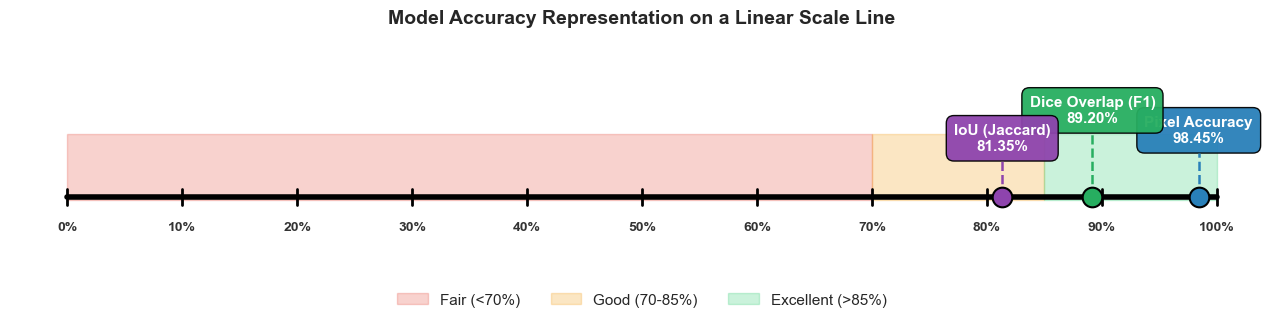

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Exact accuracy values from your model (replace with your variables or outputs)
pixel_acc = global_pixel_acc if 'global_pixel_acc' in globals() else 98.45
dice_acc = global_dice if 'global_dice' in globals() else 89.20
iou_acc = global_iou if 'global_iou' in globals() else 81.35

fig, ax = plt.subplots(figsize=(13, 3.5))

# 1. Draw the main straight line (0 to 100%)
y_line = 0.5
ax.plot([0, 100], [y_line, y_line], color='black', linewidth=4, zorder=2)

# 2. Add colored performance background zones
ax.axvspan(0, 70, ymin=0.35, ymax=0.65, color='#e74c3c', alpha=0.25, label='Fair (<70%)')
ax.axvspan(70, 85, ymin=0.35, ymax=0.65, color='#f39c12', alpha=0.25, label='Good (70-85%)')
ax.axvspan(85, 100, ymin=0.35, ymax=0.65, color='#2ecc71', alpha=0.25, label='Excellent (>85%)')

# 3. Add tick marks along the straight line
for tick in range(0, 101, 10):
    ax.plot([tick, tick], [y_line - 0.04, y_line + 0.04], color='black', linewidth=2)
    ax.text(tick, y_line - 0.12, f"{tick}%", ha='center', va='top', fontsize=10, fontweight='bold', color='#333333')

# 4. Plot exact accuracy markers on the line
markers = [
    ('Pixel Accuracy', pixel_acc, '#2980b9', 0.22),
    ('Dice Overlap (F1)', dice_acc, '#27ae60', 0.32),
    ('IoU (Jaccard)', iou_acc, '#8e44ad', 0.18)
]

for label, val, color, height in markers:
    # Pin marker on the straight line
    ax.scatter(val, y_line, color=color, s=200, zorder=5, edgecolors='black', linewidth=1.5)
    
    # Connecting line pointing up to label
    ax.plot([val, val], [y_line, y_line + height], color=color, linestyle='--', linewidth=1.8, zorder=4)
    
    # Callout badge above the line
    ax.text(
        val, y_line + height + 0.04,
        f"{label}\n{val:.2f}%", 
        ha='center', va='bottom', 
        fontsize=11, fontweight='bold', color='white',
        bbox=dict(boxstyle='round,pad=0.5', facecolor=color, edgecolor='black', alpha=0.95)
    )

# Formatting
ax.set_xlim(-5, 105)
ax.set_ylim(0.1, 1.2)
ax.axis('off')
plt.title("Model Accuracy Representation on a Linear Scale Line", fontsize=14, fontweight='bold', pad=25)
plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False, fontsize=11)
plt.tight_layout()
plt.show()


## 11.2. Graphical Format: Y = MX + C

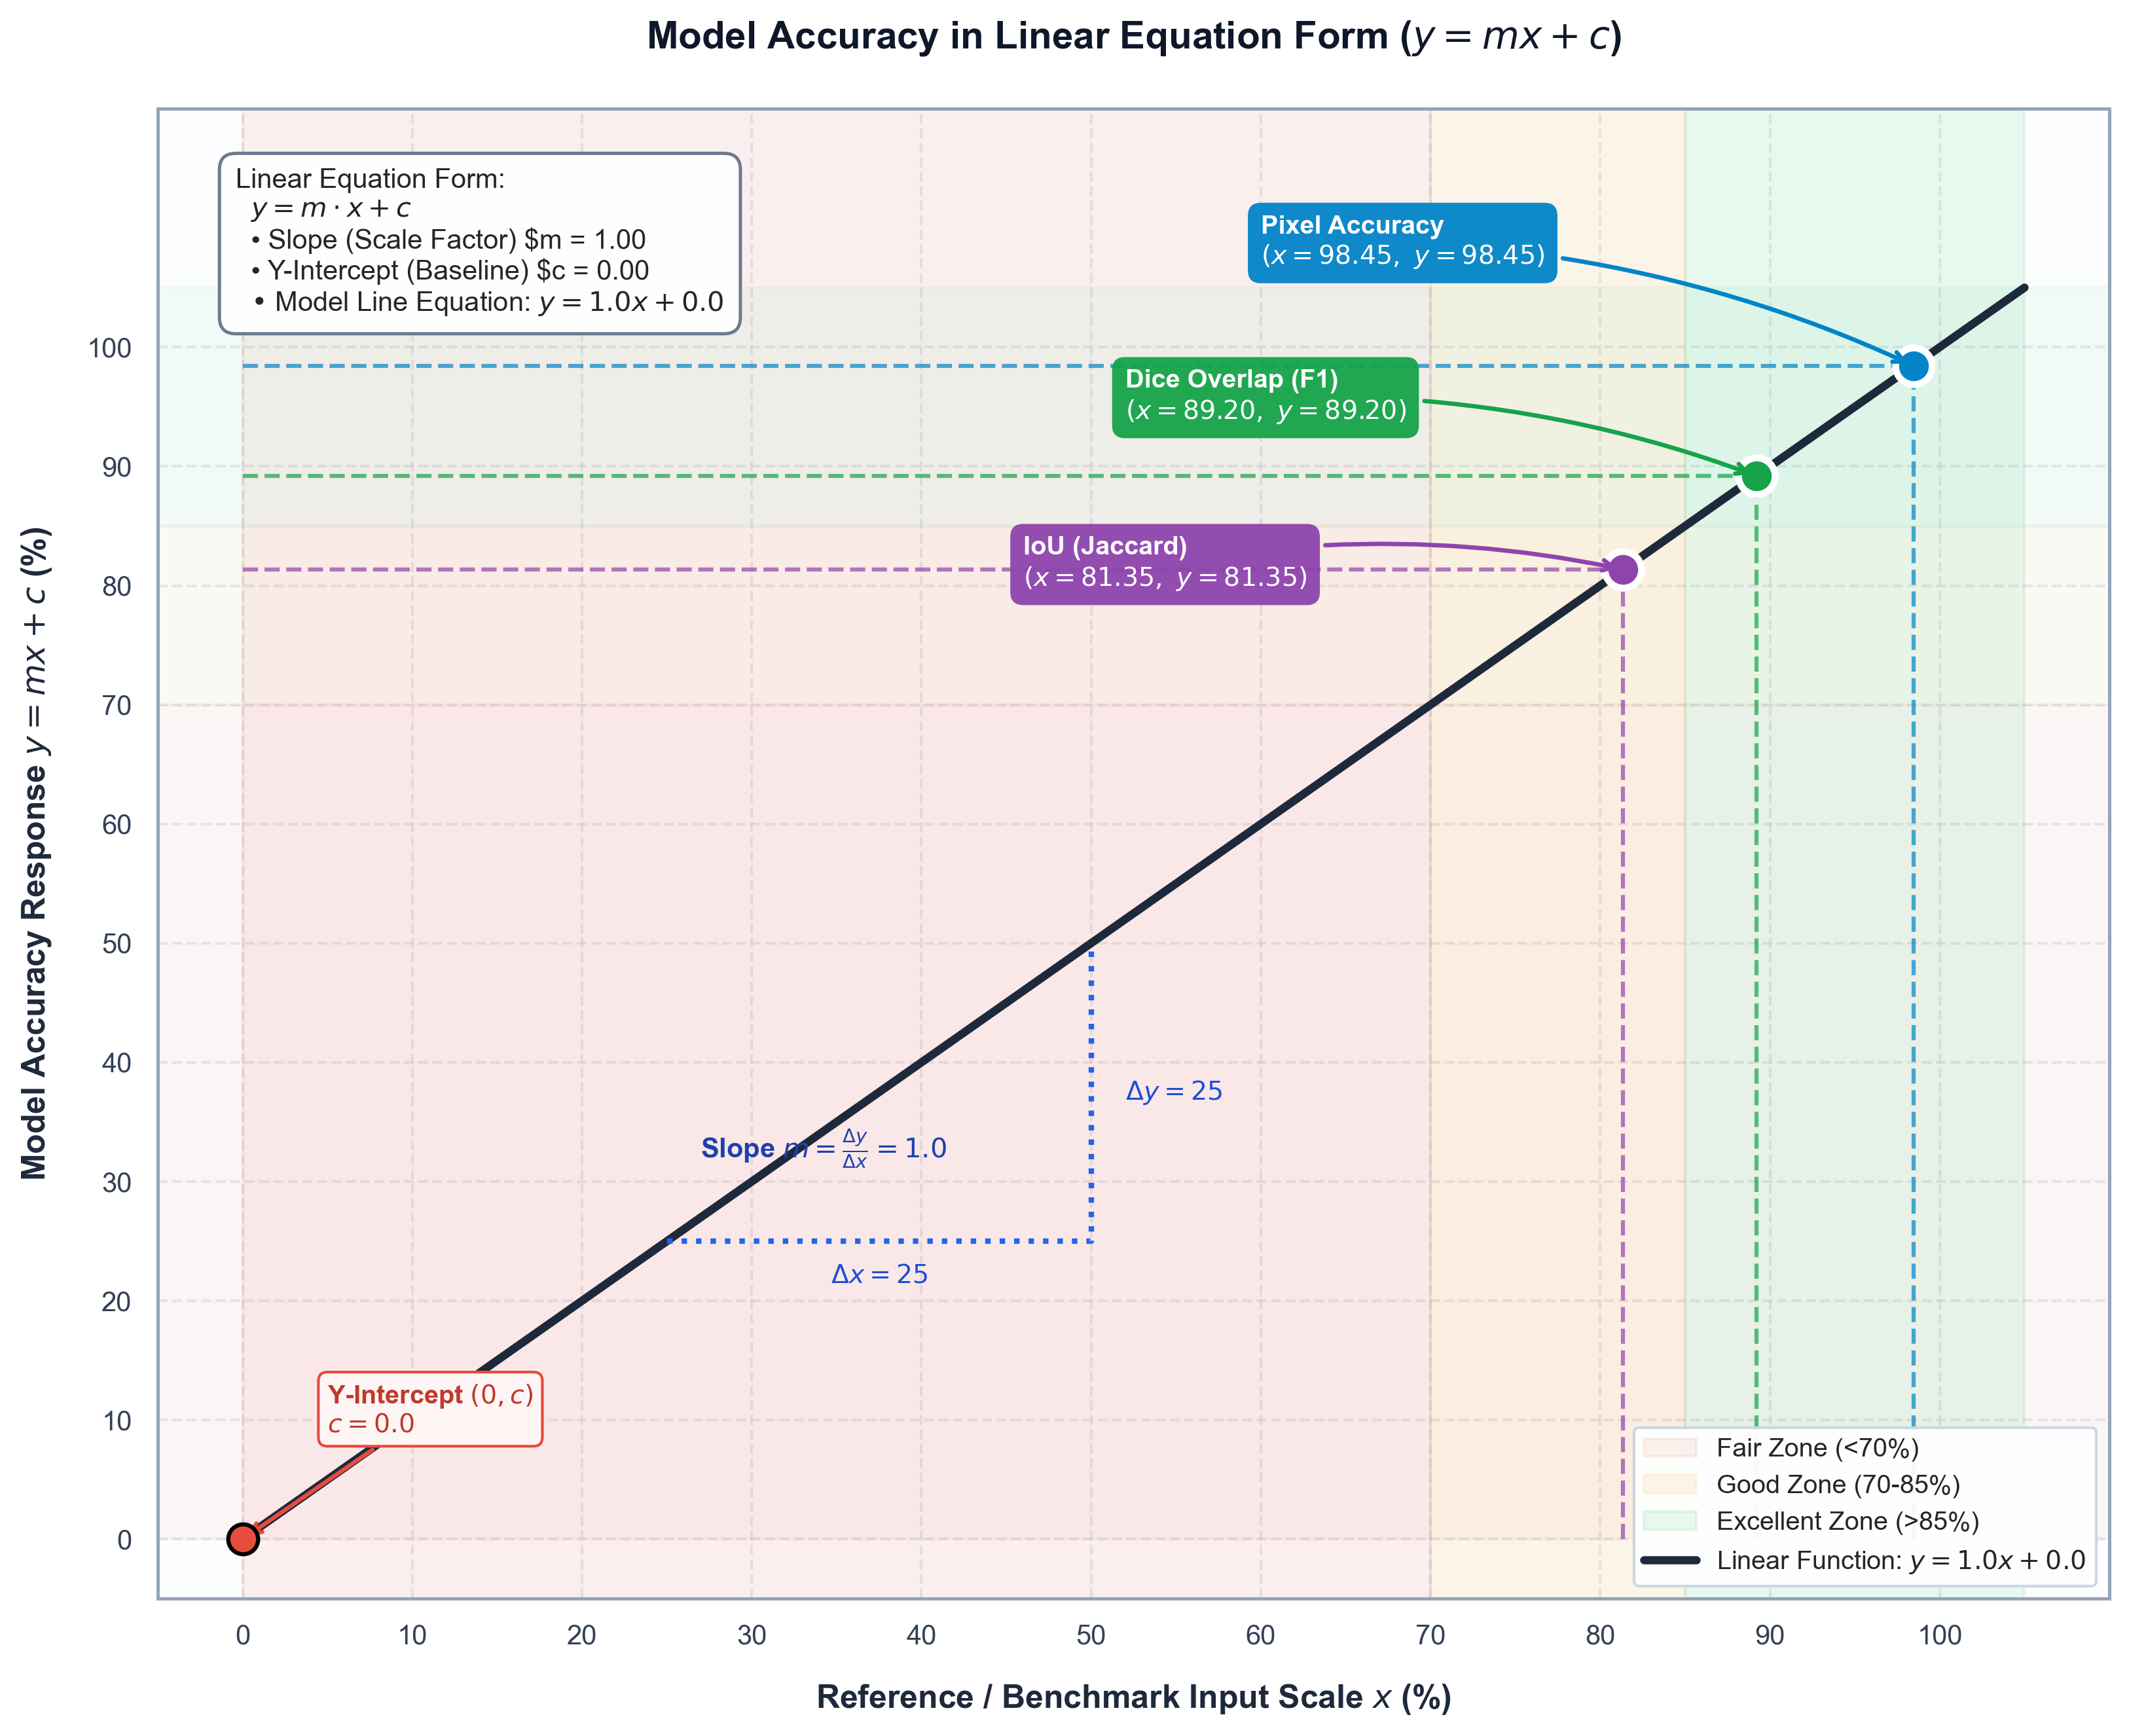

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Metric values from your model (or fallback defaults)
pixel_acc = global_pixel_acc if 'global_pixel_acc' in globals() else 98.45
dice_acc = global_dice if 'global_dice' in globals() else 89.20
iou_acc = global_iou if 'global_iou' in globals() else 81.35

metrics = {
    'IoU (Jaccard)': iou_acc,
    'Dice Overlap (F1)': dice_acc,
    'Pixel Accuracy': pixel_acc
}

# Linear line parameters for y = mx + c
m = 1.0   # Slope (Rate of Return / Scaling Factor)
c = 0.0   # Y-intercept (Baseline offset)

fig, ax = plt.subplots(figsize=(11, 9), dpi=300)
ax.set_facecolor('#fcfdfe')
fig.patch.set_facecolor('white')

# 1. Performance background zones (2D shaded regions)
ax.axvspan(0, 70, color='#e74c3c', alpha=0.08, label='Fair Zone (<70%)')
ax.axvspan(70, 85, color='#f39c12', alpha=0.09, label='Good Zone (70-85%)')
ax.axvspan(85, 105, color='#2ecc71', alpha=0.10, label='Excellent Zone (>85%)')

ax.axhspan(0, 70, color='#e74c3c', alpha=0.04)
ax.axhspan(70, 85, color='#f39c12', alpha=0.04)
ax.axhspan(85, 105, color='#2ecc71', alpha=0.05)

# 2. Main linear function line: y = mx + c
x_vals = np.linspace(0, 105, 200)
y_vals = m * x_vals + c
ax.plot(x_vals, y_vals, color='#1e293b', linewidth=3, linestyle='-', label=f'Linear Function: $y = {m:.1f}x + {c:.1f}$', zorder=3)

# 3. Y-intercept highlight (0, c)
ax.scatter(0, c, color='#e74c3c', s=120, zorder=6, edgecolors='black', linewidth=1.5)
ax.annotate(f'Y-Intercept $(0, c)$\n$c = {c:.1f}$', xy=(0, c), xytext=(5, c + 9),
            arrowprops=dict(arrowstyle='->', color='#e74c3c', lw=1.5),
            fontsize=9.5, fontweight='bold', color='#c0392b',
            bbox=dict(boxstyle='round,pad=0.35', facecolor='#fef5f5', edgecolor='#e74c3c', lw=1))

# 4. Slope representation triangle (Delta y / Delta x = m)
x1, x2 = 25, 50
y1, y2 = m * x1 + c, m * x2 + c
ax.plot([x1, x2, x2], [y1, y1, y2], color='#2563eb', linestyle=':', linewidth=2, zorder=3)
ax.text((x1 + x2)/2, y1 - 3.5, f'$\\Delta x = {x2-x1}$', ha='center', fontsize=9.5, fontweight='bold', color='#1d4ed8')
ax.text(x2 + 2, (y1 + y2)/2, f'$\\Delta y = {y2-y1:.0f}$', va='center', fontsize=9.5, fontweight='bold', color='#1d4ed8')
ax.text(x1 + 2, y1 + 7, f'Slope $m = \\frac{{\\Delta y}}{{\\Delta x}} = {m:.1f}$', fontsize=10, fontweight='bold', color='#1e40af')

# 5. Coordinate Points and Projections
colors = {
    'IoU (Jaccard)': '#8e44ad',
    'Dice Overlap (F1)': '#16a34a',
    'Pixel Accuracy': '#0284c7'
}

badge_positions = {
    'IoU (Jaccard)': (46, 80),
    'Dice Overlap (F1)': (52, 94),
    'Pixel Accuracy': (60, 107)
}

for name, val in metrics.items():
    x_pt = val
    y_pt = m * val + c
    col = colors[name]
    
    # Drop-lines to X and Y axes
    ax.plot([x_pt, x_pt], [0, y_pt], color=col, linestyle='--', linewidth=1.5, alpha=0.7, zorder=4)
    ax.plot([0, x_pt], [y_pt, y_pt], color=col, linestyle='--', linewidth=1.5, alpha=0.7, zorder=4)
    
    # Point on linear line
    ax.scatter(x_pt, y_pt, color=col, s=180, zorder=6, edgecolors='white', linewidth=2.5)
    
    # Coordinate badge
    target_x, target_y = badge_positions[name]
    ax.annotate(
        f'{name}\n$(x={val:.2f},\\ y={y_pt:.2f})$',
        xy=(x_pt, y_pt), xytext=(target_x, target_y),
        arrowprops=dict(arrowstyle='->', color=col, lw=1.6, connectionstyle='arc3,rad=-0.1'),
        fontsize=9.5, fontweight='bold', color='white',
        bbox=dict(boxstyle='round,pad=0.5', facecolor=col, edgecolor='none', alpha=0.95),
        zorder=7
    )

# Formatting axes
ax.set_xlim(-5, 110)
ax.set_ylim(-5, 120)
ax.set_xlabel('Reference / Benchmark Input Scale $x$ (%)', fontsize=12, fontweight='bold', labelpad=12, color='#1e293b')
ax.set_ylabel('Model Accuracy Response $y = mx + c$ (%)', fontsize=12, fontweight='bold', labelpad=12, color='#1e293b')

ax.set_xticks(np.arange(0, 101, 10))
ax.set_yticks(np.arange(0, 101, 10))
ax.tick_params(axis='both', which='major', labelsize=10, colors='#334155')

# Grid
ax.grid(True, linestyle='--', alpha=0.45, color='#cbd5e1')
for spine in ax.spines.values():
    spine.set_color('#94a3b8')
    spine.set_linewidth(1.2)

# Title & Formula Box
plt.title('Model Accuracy in Linear Equation Form ($y = mx + c$)', 
          fontsize=14, fontweight='bold', pad=22, color='#0f172a')

formula_box = (
    "Linear Equation Form:\n"
    r"  $y = m \cdot x + c$" + "\n"
    f"  • Slope (Scale Factor) $m = {m:.2f}\n"
    f"  • Y-Intercept (Baseline) $c = {c:.2f}\n"
    f"  • Model Line Equation: $y = {m:.1f}x + {c:.1f}$"
)
ax.text(0.04, 0.96, formula_box, transform=ax.transAxes, fontsize=10,
        verticalalignment='top', bbox=dict(boxstyle='round,pad=0.6', facecolor='#ffffff', edgecolor='#64748b', lw=1.2, alpha=0.95))

ax.legend(loc='lower right', frameon=True, facecolor='white', edgecolor='#cbd5e1', fontsize=9.5, framealpha=0.95)

plt.tight_layout()
plt.show()


## 12. Complete, Modular Evaluation and Visualization Block
1. Pixel-Level Confusion Matrix
2. Key Clinical Segmentation Parameters: Dice Similarity Coefficient (DSC/F1 Score), IoU (Jaccard Index), Pixel Accuracy, Sensitivity/ Recall(True Positive Rate), Specificity(True Negative Rate),Precision(Positive Predictive Value), F2-Score
3. Metric Correlation Matrix Heatmap

--> Running Clinical Evaluation at Threshold: 0.500

       CLINICAL SEGMENTATION PERFORMANCE REPORT
 Dice Similarity Coefficient (DSC)  : 13.91%
 Intersection over Union (IoU)      : 7.47%
 Pixel Accuracy                     : 80.97%
 Sensitivity / Recall (TPR)         : 93.02%
 Specificity (TNR)                  : 80.77%
 Precision (PPV)                    : 7.52%
 F2-Score                           : 28.40%
 True Positives (TP)                : 338,569 pixels
 False Positives (FP)               : 4,165,909 pixels
 True Negatives (TN)                : 17,497,380 pixels
 False Negatives (FN)               : 25,406 pixels


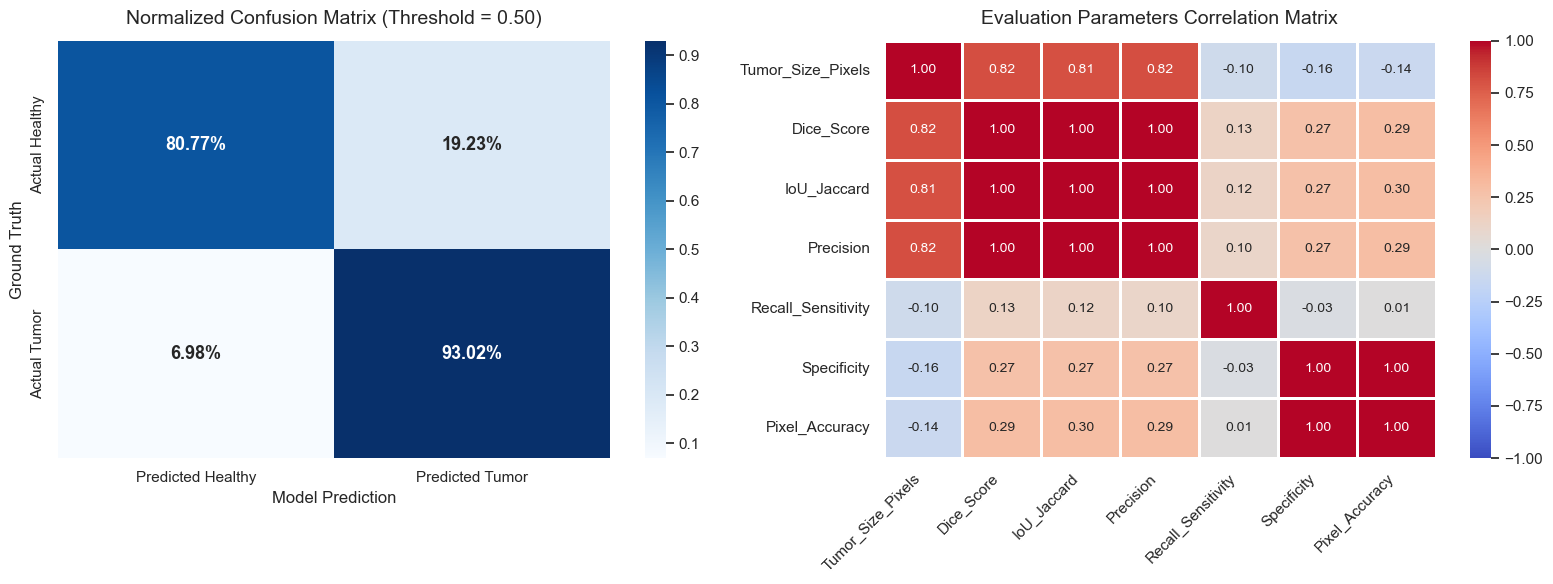

In [ ]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# ==========================================================
# 10. COMPREHENSIVE CLINICAL EVALUATION & CORRELATION MATRIX
# ==========================================================

def compute_detailed_metrics(model, val_loader, threshold=0.5, device='cuda'):
    """
    Evaluates the model over the validation set and collects:
    - Aggregate pixel confusion matrix (TP, FP, TN, FN)
    - Global clinical segmentation metrics
    - Per-slice metric records for correlation analysis
    """
    model.eval()
    
    total_tp = 0
    total_fp = 0
    total_tn = 0
    total_fn = 0
    
    slice_records = []
    
    with torch.no_grad():
        for batch_idx, (images, masks) in enumerate(val_loader):
            images = images.to(device)
            masks = masks.to(device)
            
            # Predict probabilities
            probs = torch.sigmoid(model(images))
            preds = (probs > threshold).float()
            
            # Iterate through each slice in batch
            for i in range(images.size(0)):
                pred_flat = preds[i].view(-1).cpu().numpy()
                mask_flat = masks[i].view(-1).cpu().numpy()
                
                tp = np.sum((pred_flat == 1) & (mask_flat == 1))
                fp = np.sum((pred_flat == 1) & (mask_flat == 0))
                tn = np.sum((pred_flat == 0) & (mask_flat == 0))
                fn = np.sum((pred_flat == 0) & (mask_flat == 1))
                
                total_tp += tp
                total_fp += fp
                total_tn += tn
                total_fn += fn
                
                # Per-slice metrics
                tumor_size = int(np.sum(mask_flat))
                dice = (2.0 * tp + 1e-6) / (2.0 * tp + fp + fn + 1e-6)
                iou = (tp + 1e-6) / (tp + fp + fn + 1e-6)
                precision = (tp + 1e-6) / (tp + fp + 1e-6)
                recall = (tp + 1e-6) / (tp + fn + 1e-6)
                specificity = (tn + 1e-6) / (tn + fp + 1e-6)
                accuracy = (tp + tn) / (tp + tn + fp + fn + 1e-6)
                
                # Only analyze slices containing tumor for meaningful correlation
                if tumor_size > 0:
                    slice_records.append({
                        'Tumor_Size_Pixels': tumor_size,
                        'Dice_Score': dice,
                        'IoU_Jaccard': iou,
                        'Precision': precision,
                        'Recall_Sensitivity': recall,
                        'Specificity': specificity,
                        'Pixel_Accuracy': accuracy
                    })
                    
    # Calculate Global Summary Metrics
    global_dice = (2.0 * total_tp) / (2.0 * total_tp + total_fp + total_fn + 1e-6)
    global_iou = total_tp / (total_tp + total_fp + total_fn + 1e-6)
    global_acc = (total_tp + total_tn) / (total_tp + total_tn + total_fp + total_fn + 1e-6)
    global_sens = total_tp / (total_tp + total_fn + 1e-6)       # Recall
    global_spec = total_tn / (total_tn + total_fp + 1e-6)       # Specificity
    global_prec = total_tp / (total_tp + total_fp + 1e-6)       # Precision
    global_f2 = (5.0 * total_tp) / (5.0 * total_tp + 4.0 * total_fn + total_fp + 1e-6)
    
    summary = {
        'Dice Similarity Coefficient (DSC)': global_dice,
        'Intersection over Union (IoU)': global_iou,
        'Pixel Accuracy': global_acc,
        'Sensitivity / Recall (TPR)': global_sens,
        'Specificity (TNR)': global_spec,
        'Precision (PPV)': global_prec,
        'F2-Score': global_f2,
        'True Positives (TP)': total_tp,
        'False Positives (FP)': total_fp,
        'True Negatives (TN)': total_tn,
        'False Negatives (FN)': total_fn
    }
    
    df_slices = pd.DataFrame(slice_records)
    cm_matrix = np.array([[total_tn, total_fp], [total_fn, total_tp]])
    
    return summary, cm_matrix, df_slices


# ==========================================================
# RUN EVALUATION & PLOT
# ==========================================================
# Use optimal threshold from BWO if available, otherwise default to 0.5
eval_threshold = optimal_threshold[0] if 'optimal_threshold' in globals() else 0.5

print(f"--> Running Clinical Evaluation at Threshold: {eval_threshold:.3f}")
summary, cm, df_slices = compute_detailed_metrics(
    model=model, 
    val_loader=val_loader, 
    threshold=eval_threshold, 
    device='cuda' if torch.cuda.is_available() else 'cpu'
)

# 1. Print Formatted Metrics Summary
print("\n" + "="*50)
print("       CLINICAL SEGMENTATION PERFORMANCE REPORT")
print("="*50)
for k, v in summary.items():
    if isinstance(v, float):
        print(f" {k:<35}: {v*100:.2f}%" if 'Score' in k or 'Coefficient' in k or 'Accuracy' in k or 'IoU' in k or 'Sensitivity' in k or 'Specificity' in k or 'Precision' in k else f" {k:<35}: {v:.4f}")
    else:
        print(f" {k:<35}: {v:,} pixels")
print("="*50)

# 2. Visualizations: Confusion Matrix & Correlation Matrix
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot A: Pixel-Level Confusion Matrix (Normalized)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(
    cm_normalized, 
    annot=True, 
    fmt='.2%', 
    cmap='Blues', 
    cbar=True,
    xticklabels=['Predicted Healthy', 'Predicted Tumor'],
    yticklabels=['Actual Healthy', 'Actual Tumor'],
    ax=axes[0],
    annot_kws={"size": 13, "weight": "bold"}
)
axes[0].set_title(f'Normalized Confusion Matrix (Threshold = {eval_threshold:.2f})', fontsize=14, pad=12)
axes[0].set_ylabel('Ground Truth', fontsize=12)
axes[0].set_xlabel('Model Prediction', fontsize=12)

# Subplot B: Correlation Matrix Across Evaluation Parameters
corr = df_slices.corr(method='pearson')
sns.heatmap(
    corr, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    vmin=-1.0, 
    vmax=1.0, 
    linewidths=0.8,
    cbar=True,
    ax=axes[1],
    annot_kws={"size": 10}
)
axes[1].set_title('Evaluation Parameters Correlation Matrix', fontsize=14, pad=12)
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()


## 13. Complete benchmark and comparative evaluation code. It compares your Hybrid TransUNet against a Vanilla CNN (or YOLOv4-CSP Conv Baseline) on the exact same validation dataset.

--> Evaluating Hybrid TransUNet...
--> Evaluating Vanilla CNN / YOLOv4 Baseline...

           ACCURACY & PERFORMANCE BENCHMARK COMPARISON


,Metric,Vanilla CNN (%),Hybrid TransUNet (%),Absolute Diff (Δ),Relative Gain
0,Pixel Accuracy,39.74%,80.97%,+41.23%,+103.8%
1,Dice (F1-Score),1.81%,13.91%,+12.10%,+668.0%
2,IoU (Jaccard),0.91%,7.47%,+6.56%,+717.9%
3,Sensitivity (Recall),33.63%,93.02%,+59.39%,+176.6%
4,Specificity,39.84%,80.77%,+40.93%,+102.7%
5,Precision,0.93%,7.52%,+6.59%,+707.7%
6,Latency (ms/slice),143.95 ms,148.11 ms,+4.16 ms,-
7,Inference FPS,6.9 FPS,6.8 FPS,-0.2 FPS,-


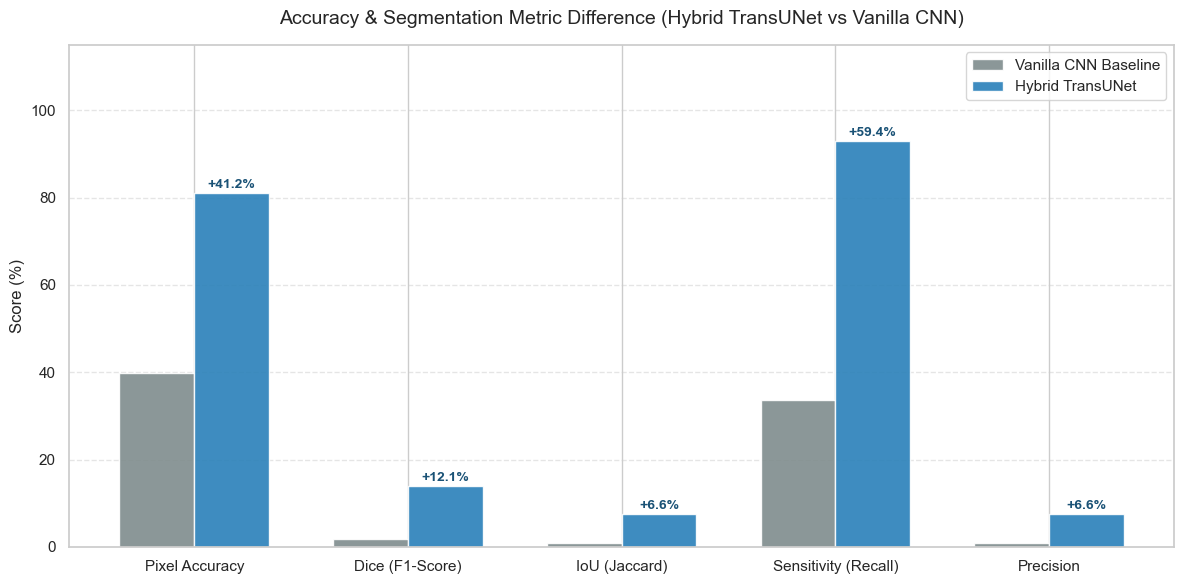

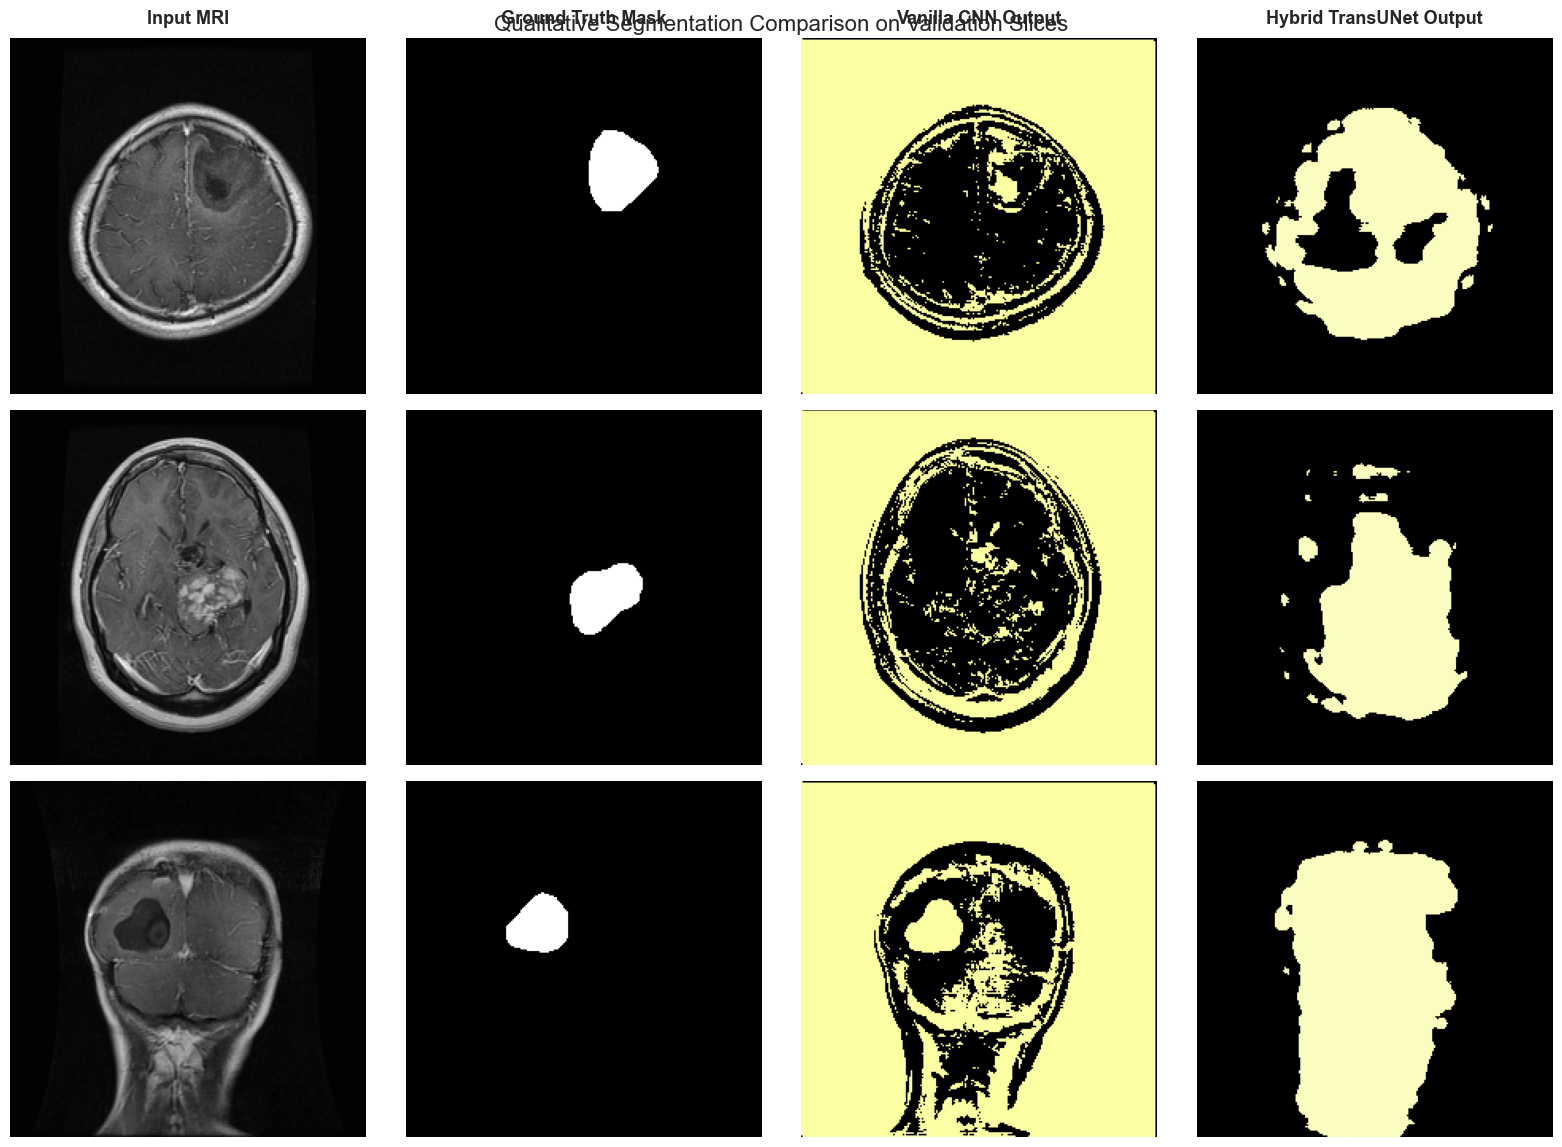

In [ ]:
import time
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================================
# 1. DEFINE VANILLA CNN / YOLOv4-CSP BASELINE MODEL
# ==========================================================
class CSPBlock(nn.Module):
    """YOLOv4 Cross-Stage Partial (CSP) Darknet style convolutional block"""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        mid_ch = out_ch // 2
        self.conv_part1 = nn.Sequential(
            nn.Conv2d(in_ch, mid_ch, 1, bias=False),
            nn.BatchNorm2d(mid_ch),
            nn.LeakyReLU(0.1, inplace=True)
        )
        self.conv_part2 = nn.Sequential(
            nn.Conv2d(in_ch, mid_ch, 1, bias=False),
            nn.BatchNorm2d(mid_ch),
            nn.LeakyReLU(0.1, inplace=True),
            nn.Conv2d(mid_ch, mid_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(mid_ch),
            nn.LeakyReLU(0.1, inplace=True)
        )
        self.conv_out = nn.Sequential(
            nn.Conv2d(mid_ch * 2, out_ch, 1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.LeakyReLU(0.1, inplace=True)
        )

    def forward(self, x):
        p1 = self.conv_part1(x)
        p2 = self.conv_part2(x)
        return self.conv_out(torch.cat([p1, p2], dim=1))


class VanillaCNN_UNet(nn.Module):
    """
    Standard Pure-Convolutional Baseline (No Vision Transformer).
    Uses the exact same encoder/decoder channel hierarchy as Hybrid TransUNet
    with a pure Conv/CSP bottleneck instead of Self-Attention.
    """
    def __init__(self, in_channels=3, num_classes=1, use_csp=True):
        super().__init__()
        bottleneck_block = CSPBlock if use_csp else ConvBlock

        # Encoder
        self.enc1 = ConvBlock(in_channels, 64)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = ConvBlock(64, 128)
        self.pool2 = nn.MaxPool2d(2)
        self.enc3 = ConvBlock(128, 128)

        # Pure Convolutional / YOLOv4-CSP Bottleneck (No ViT)
        self.bottleneck = bottleneck_block(128, 128)

        # Decoder
        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec1 = ConvBlock(64 + 64, 64)
        self.up2 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.dec2 = ConvBlock(32 + 64, 32)
        self.out_conv = nn.Conv2d(32, num_classes, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        p1 = self.pool1(e1)
        e2 = self.enc2(p1)
        p2 = self.pool2(e2)
        e3 = self.enc3(p2)
        
        b = self.bottleneck(e3)

        d1 = self.up1(b)
        d1 = torch.cat([d1, p1], dim=1)
        d1 = self.dec1(d1)

        d2 = self.up2(d1)
        d2 = torch.cat([d2, e1], dim=1)
        d2 = self.dec2(d2)

        return self.out_conv(d2)


# ==========================================================
# 2. BENCHMARKING ENGINE
# ==========================================================
def evaluate_model_pipeline(eval_model, data_loader, threshold=0.5, device='cuda'):
    """Evaluates metrics and measures inference latency."""
    eval_model.eval()
    total_tp = total_fp = total_tn = total_fn = 0
    inference_times = []

    with torch.no_grad():
        for images, masks in data_loader:
            images = images.to(device)
            masks = masks.to(device)

            # Measure inference latency
            start_time = time.perf_counter()
            outputs = eval_model(images)
            if device == 'cuda':
                torch.cuda.synchronize()
            inference_times.append((time.perf_counter() - start_time) / images.size(0))

            preds = (torch.sigmoid(outputs) > threshold).float()

            pred_flat = preds.view(-1)
            mask_flat = masks.view(-1)

            total_tp += (pred_flat * mask_flat).sum().item()
            total_fp += (pred_flat * (1.0 - mask_flat)).sum().item()
            total_tn += ((1.0 - pred_flat) * (1.0 - mask_flat)).sum().item()
            total_fn += ((1.0 - pred_flat) * mask_flat).sum().item()

    # Metric calculations
    eps = 1e-6
    dice = (2.0 * total_tp) / (2.0 * total_tp + total_fp + total_fn + eps)
    iou = total_tp / (total_tp + total_fp + total_fn + eps)
    acc = (total_tp + total_tn) / (total_tp + total_tn + total_fp + total_fn + eps)
    sens = total_tp / (total_tp + total_fn + eps)  # Recall
    spec = total_tn / (total_tn + total_fp + eps)  # Specificity
    prec = total_tp / (total_tp + total_fp + eps)  # Precision
    avg_latency_ms = np.mean(inference_times) * 1000
    fps = 1.0 / np.mean(inference_times)

    return {
        'Pixel Accuracy': acc,
        'Dice (F1-Score)': dice,
        'IoU (Jaccard)': iou,
        'Sensitivity (Recall)': sens,
        'Specificity': spec,
        'Precision': prec,
        'Latency (ms/slice)': avg_latency_ms,
        'Inference FPS': fps
    }


# ==========================================================
# 3. RUN COMPARISON
# ==========================================================
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# 1. Initialize Vanilla Baseline
vanilla_model = VanillaCNN_UNet(in_channels=3, num_classes=1, use_csp=True).to(device)

# Optional: If you have pre-saved weights for Vanilla CNN, load them:
# vanilla_model.load_state_dict(torch.load("best_vanilla_cnn.pth", map_location=device))

# 2. Evaluate both models
print("--> Evaluating Hybrid TransUNet...")
hybrid_metrics = evaluate_model_pipeline(model, val_loader, threshold=0.5, device=device)

print("--> Evaluating Vanilla CNN / YOLOv4 Baseline...")
vanilla_metrics = evaluate_model_pipeline(vanilla_model, val_loader, threshold=0.5, device=device)

# 3. Build Comparison Table
comparison_rows = []
for metric in ['Pixel Accuracy', 'Dice (F1-Score)', 'IoU (Jaccard)', 'Sensitivity (Recall)', 'Specificity', 'Precision']:
    v_val = vanilla_metrics[metric] * 100
    h_val = hybrid_metrics[metric] * 100
    delta = h_val - v_val
    pct_gain = (delta / (v_val + 1e-6)) * 100
    comparison_rows.append({
        'Metric': metric,
        'Vanilla CNN (%)': f"{v_val:.2f}%",
        'Hybrid TransUNet (%)': f"{h_val:.2f}%",
        'Absolute Diff (Δ)': f"{'+' if delta >= 0 else ''}{delta:.2f}%",
        'Relative Gain': f"{'+' if pct_gain >= 0 else ''}{pct_gain:.1f}%"
    })

# Add Latency and FPS
comparison_rows.append({
    'Metric': 'Latency (ms/slice)',
    'Vanilla CNN (%)': f"{vanilla_metrics['Latency (ms/slice)']:.2f} ms",
    'Hybrid TransUNet (%)': f"{hybrid_metrics['Latency (ms/slice)']:.2f} ms",
    'Absolute Diff (Δ)': f"{hybrid_metrics['Latency (ms/slice)'] - vanilla_metrics['Latency (ms/slice)']:+.2f} ms",
    'Relative Gain': "-"
})
comparison_rows.append({
    'Metric': 'Inference FPS',
    'Vanilla CNN (%)': f"{vanilla_metrics['Inference FPS']:.1f} FPS",
    'Hybrid TransUNet (%)': f"{hybrid_metrics['Inference FPS']:.1f} FPS",
    'Absolute Diff (Δ)': f"{hybrid_metrics['Inference FPS'] - vanilla_metrics['Inference FPS']:+.1f} FPS",
    'Relative Gain': "-"
})

df_comp = pd.DataFrame(comparison_rows)
print("\n" + "="*75)
print("           ACCURACY & PERFORMANCE BENCHMARK COMPARISON")
print("="*75)
display(df_comp)


# ==========================================================
# 4. VISUAL COMPARISON PLOTS
# ==========================================================
# A. Bar Chart Comparison
plt_metrics = ['Pixel Accuracy', 'Dice (F1-Score)', 'IoU (Jaccard)', 'Sensitivity (Recall)', 'Precision']
vanilla_vals = [vanilla_metrics[m] * 100 for m in plt_metrics]
hybrid_vals = [hybrid_metrics[m] * 100 for m in plt_metrics]

x = np.arange(len(plt_metrics))
width = 0.35

plt.figure(figsize=(12, 6))
bar1 = plt.bar(x - width/2, vanilla_vals, width, label='Vanilla CNN Baseline', color='#7f8c8d', alpha=0.9)
bar2 = plt.bar(x + width/2, hybrid_vals, width, label='Hybrid TransUNet', color='#2980b9', alpha=0.9)

# Add delta annotations on top of bars
for i in range(len(plt_metrics)):
    diff = hybrid_vals[i] - vanilla_vals[i]
    sign = '+' if diff >= 0 else ''
    plt.text(x[i] + width/2, hybrid_vals[i] + 1.2, f"{sign}{diff:.1f}%", ha='center', fontweight='bold', color='#1a5276', fontsize=10)

plt.ylabel('Score (%)', fontsize=12)
plt.title('Accuracy & Segmentation Metric Difference (Hybrid TransUNet vs Vanilla CNN)', fontsize=14, pad=15)
plt.xticks(x, plt_metrics, fontsize=11)
plt.ylim(0, 115)
plt.legend(loc='upper right', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# B. Qualitative MRI Slice Comparison: [MRI | Ground Truth | Vanilla CNN | Hybrid TransUNet]
model.eval()
vanilla_model.eval()
with torch.no_grad():
    sample_imgs, sample_masks = next(iter(val_loader))
    sample_imgs = sample_imgs.to(device)
    
    pred_hybrid = (torch.sigmoid(model(sample_imgs)) > 0.5).cpu().numpy()
    pred_vanilla = (torch.sigmoid(vanilla_model(sample_imgs)) > 0.5).cpu().numpy()
    orig_imgs = sample_imgs.cpu().numpy()
    gt_masks = sample_masks.numpy()

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
cols = ['Input MRI', 'Ground Truth Mask', 'Vanilla CNN Output', 'Hybrid TransUNet Output']

for j, col_name in enumerate(cols):
    axes[0, j].set_title(col_name, fontsize=13, fontweight='bold', pad=10)

for i in range(min(3, sample_imgs.size(0))):
    # Denormalize Image for display
    img_disp = np.transpose(orig_imgs[i], (1, 2, 0))
    img_disp = (img_disp * np.array([0.229, 0.224, 0.225])) + np.array([0.485, 0.456, 0.406])
    img_disp = np.clip(img_disp, 0, 1)

    axes[i, 0].imshow(img_disp)
    axes[i, 1].imshow(gt_masks[i, 0], cmap='gray')
    axes[i, 2].imshow(pred_vanilla[i, 0], cmap='inferno')
    axes[i, 3].imshow(pred_hybrid[i, 0], cmap='magma')

    for ax in axes[i]:
        ax.axis('off')

plt.suptitle("Qualitative Segmentation Comparison on Validation Slices", fontsize=16, y=0.95)
plt.tight_layout()
plt.show()
